Importo las librerias necesarias para el analisis

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import warnings
warnings.filterwarnings('ignore')

sns.set_theme(style='whitegrid')
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', lambda x: f'{x:,.2f}')

Exploración inicial de los datos

Descripción general de los datos

In [2]:
#Leo el dataset
dataset = pd.read_excel('data/BD_creditos.xlsx')

In [3]:
#Guardo una copia de los datos originales (sin tocar) para usarla despues en las reglas de validacion
dataset_original = dataset.copy()

In [4]:
#Visualizo el contenido del dataset
dataset.head()

,tipo_credito,fecha_prestamo,capital_prestado,plazo_meses,edad_cliente,tipo_laboral,salario_cliente,total_otros_prestamos,cuota_pactada,puntaje,puntaje_datacredito,cant_creditosvigentes,huella_consulta,saldo_mora,saldo_total,saldo_principal,saldo_mora_codeudor,creditos_sectorFinanciero,creditos_sectorCooperativo,creditos_sectorReal,promedio_ingresos_datacredito,tendencia_ingresos,Pago_atiempo
0,4,2025-01-07 14:40:36,"1,852,560.00",12,32,Empleado,3500000,1000000,128650,95.23,795.00,0,2,0.00,0.00,NaN,NaN,0,0,0,"916,148.00",Creciente,1
1,4,2025-01-09 11:18:48,"3,181,080.00",6,34,Empleado,5000000,2000000,441817,95.23,796.00,0,7,0.00,0.00,NaN,NaN,0,0,0,"4,473,774.00",Creciente,1
2,9,2024-12-26 18:52:57,"670,200.00",5,34,Independiente,5000000,2000000,108632,95.23,727.00,5,0,0.00,"274,561.00","274,561.00",NaN,2,0,1,NaN,NaN,1
3,9,2024-12-04 14:20:50,"506,806.80",2,25,Independiente,3000000,900000,199684,95.23,864.00,8,1,0.00,"27,564.00","27,564.00",NaN,1,0,6,NaN,NaN,1
4,4,2025-04-30 18:41:57,"999,780.00",10,26,Empleado,2000000,600000,92509,95.23,771.00,0,3,0.00,0.00,NaN,NaN,0,0,0,"61,000.00",Creciente,1


In [5]:
#Visualizo el numero de filas y columnas
print(f"Filas: {dataset.shape[0]:,} | Columnas: {dataset.shape[1]}")

Filas: 10,763 | Columnas: 23


In [6]:
#Visualizo la informacion (tipos de datos y no nulos) del dataset
dataset.info()

<class 'pandas.DataFrame'>
RangeIndex: 10763 entries, 0 to 10762
Data columns (total 23 columns):
 #   Column                         Non-Null Count  Dtype         
---  ------                         --------------  -----         
 0   tipo_credito                   10763 non-null  int64         
 1   fecha_prestamo                 10763 non-null  datetime64[us]
 2   capital_prestado               10763 non-null  float64       
 3   plazo_meses                    10763 non-null  int64         
 4   edad_cliente                   10763 non-null  int64         
 5   tipo_laboral                   10763 non-null  str           
 6   salario_cliente                10763 non-null  int64         
 7   total_otros_prestamos          10763 non-null  int64         
 8   cuota_pactada                  10763 non-null  int64         
 9   puntaje                        10763 non-null  float64       
 10  puntaje_datacredito            10757 non-null  float64       
 11  cant_creditosvigentes     

In [7]:
#Reviso si hay registros duplicados
print('Registros duplicados:', dataset.duplicated().sum())

Registros duplicados: 0


In [8]:
#Visualizo el numero de registros, promedio, desviacion estandar,
#valor minimo, cuartiles y valor maximo (antes de corregir tipos de datos)
dataset.describe().T

,count,mean,min,25%,50%,75%,max,std
tipo_credito,"10,763.00",5.41,4.00,4.00,4.00,9.00,68.00,2.34
fecha_prestamo,10763,2025-04-16 23:06:02.111121,2024-11-26 09:17:04,2025-01-20 17:33:07.500000,2025-03-27 16:23:12,2025-06-16 13:27:58,2026-04-26 18:43:52,NaN
capital_prestado,"10,763.00","2,434,315.00","360,000.00","1,224,831.00","1,921,920.00","3,084,840.00","41,444,152.80","1,909,642.76"
plazo_meses,"10,763.00",10.58,2.00,6.00,10.00,12.00,90.00,6.63
edad_cliente,"10,763.00",43.95,19.00,33.00,42.00,53.00,123.00,15.06
salario_cliente,"10,763.00","17,216,431.46",0.00,"2,000,000.00","3,000,000.00","4,875,808.00","22,000,000,000.00","355,476,717.60"
total_otros_prestamos,"10,763.00","6,238,869.65",0.00,"500,000.00","1,000,000.00","2,000,000.00","6,787,675,263.00","118,418,316.94"
cuota_pactada,"10,763.00","243,617.41","23,944.00","121,041.50","182,863.00","287,833.50","3,816,752.00","210,493.69"
puntaje,"10,763.00",91.17,-38.01,95.23,95.23,95.23,95.23,16.47
puntaje_datacredito,"10,757.00",780.79,-7.00,757.00,791.00,825.00,999.00,104.88


In [9]:
#Defino las listas de variables segun su tipo, para usarlas durante todo el analisis
variable_objetivo = 'Pago_atiempo'

variables_numericas = ['capital_prestado', 'plazo_meses', 'edad_cliente', 'salario_cliente',
                       'total_otros_prestamos', 'cuota_pactada', 'puntaje', 'puntaje_datacredito',
                       'cant_creditosvigentes', 'huella_consulta', 'saldo_mora', 'saldo_total',
                       'saldo_principal', 'saldo_mora_codeudor', 'creditos_sectorFinanciero',
                       'creditos_sectorCooperativo', 'creditos_sectorReal', 'promedio_ingresos_datacredito']

variables_categoricas = ['tipo_credito', 'tipo_laboral', 'tendencia_ingresos']

print('Numericas:', len(variables_numericas), '| Categoricas:', len(variables_categoricas), '| Fecha: 1 | Objetivo: 1')

Numericas: 18 | Categoricas: 3 | Fecha: 1 | Objetivo: 1


In [10]:
#Reviso la cantidad y el porcentaje de nulos por columna
nulos = pd.DataFrame({
    'nulos': dataset.isnull().sum(),
    'porcentaje': dataset.isnull().mean() * 100
})
nulos[nulos['nulos'] > 0].sort_values('nulos', ascending=False)

,nulos,porcentaje
tendencia_ingresos,2932,27.24
promedio_ingresos_datacredito,2930,27.22
saldo_mora_codeudor,590,5.48
saldo_principal,405,3.76
saldo_mora,156,1.45
saldo_total,156,1.45
puntaje_datacredito,6,0.06


In [11]:
#Reviso los valores de tendencia_ingresos, que es la unica variable de texto con valores raros
dataset['tendencia_ingresos'].value_counts(dropna=False).head(10)

tendencia_ingresos
Creciente      5294
NaN            2932
Decreciente    1291
Estable        1188
0                 7
8315              6
1000000           4
9147              2
158042            1
3978              1
Name: count, dtype: int64

In [12]:
#Valores de tendencia_ingresos que no son una categoria valida (son numeros guardados como texto)
categorias_validas = ['Creciente', 'Estable', 'Decreciente']
invalidos = dataset[dataset['tendencia_ingresos'].notna() & ~dataset['tendencia_ingresos'].isin(categorias_validas)]
print('Registros con un valor invalido en tendencia_ingresos:', len(invalidos))
invalidos['tendencia_ingresos'].value_counts().head(10)

Registros con un valor invalido en tendencia_ingresos: 58


tendencia_ingresos
0          7
8315       6
1000000    4
9147       2
158042     1
3978       1
168750     1
-28589     1
-566272    1
24702      1
Name: count, dtype: int64

In [13]:
#Unifico todos los nulos como NaN: en tendencia_ingresos lo que no es una categoria valida pasa a NaN
dataset.loc[~dataset['tendencia_ingresos'].isin(categorias_validas), 'tendencia_ingresos'] = np.nan

#Tambien reviso si hay textos que representen nulos en las columnas de texto (vacios, 'NA', 'null', etc.)
dataset = dataset.replace(['', ' ', 'NA', 'N/A', 'null', 'NULL', 'None', 'nan', 'NaN'], np.nan)
dataset['tendencia_ingresos'].value_counts(dropna=False)

tendencia_ingresos
Creciente      5294
NaN            2990
Decreciente    1291
Estable        1188
Name: count, dtype: int64

In [14]:
#Reviso los valores que no tienen sentido en varias variables
print('edad_cliente > 100 anos:', (dataset['edad_cliente'] > 100).sum(), '| valores:', sorted(dataset.loc[dataset['edad_cliente'] > 100, 'edad_cliente'].unique()))
print('salario_cliente <= 0:', (dataset['salario_cliente'] <= 0).sum())
print('salario_cliente > 100 millones:', (dataset['salario_cliente'] > 100_000_000).sum())
print('puntaje_datacredito <= 0:', (dataset['puntaje_datacredito'] <= 0).sum())
print('puntaje_datacredito > 950:', (dataset['puntaje_datacredito'] > 950).sum())

edad_cliente > 100 anos: 150 | valores: [np.int64(121), np.int64(122), np.int64(123)]
salario_cliente <= 0: 24
salario_cliente > 100 millones: 74
puntaje_datacredito <= 0: 146
puntaje_datacredito > 950: 6


In [15]:
#Convierto en nulos los valores imposibles
dataset.loc[dataset['edad_cliente'] > 100, 'edad_cliente'] = np.nan
dataset.loc[(dataset['salario_cliente'] <= 0) | (dataset['salario_cliente'] > 100_000_000), 'salario_cliente'] = np.nan
dataset.loc[dataset['puntaje_datacredito'] <= 0, 'puntaje_datacredito'] = np.nan

In [16]:
#saldo_principal es nulo cuando el cliente no tiene creditos vigentes?
sin_creditos = dataset['cant_creditosvigentes'] == 0
print('Clientes sin creditos vigentes:', sin_creditos.sum())
print('saldo_principal nulo:', dataset['saldo_principal'].isnull().sum())
print('Coinciden ambos casos en todos los registros:', (sin_creditos == dataset['saldo_principal'].isnull()).all())

Clientes sin creditos vigentes: 405
saldo_principal nulo: 405
Coinciden ambos casos en todos los registros: True


In [17]:
#promedio_ingresos_datacredito nulo segun el tipo laboral
dataset['promedio_ingresos_datacredito'].isnull().groupby(dataset['tipo_laboral']).mean().mul(100).round(1)

tipo_laboral
Empleado        19.00
Independiente   41.00
Name: promedio_ingresos_datacredito, dtype: float64

Eliminación de variables irrelevantes

In [18]:
#Reviso la cantidad de valores distintos por columna para detectar variables constantes o identificadores
resumen_unicos = pd.DataFrame({
    'valores_unicos': dataset.nunique(),
    'porcentaje_unicos': dataset.nunique() / len(dataset) * 100
}).sort_values('valores_unicos')
resumen_unicos

,valores_unicos,porcentaje_unicos
tipo_laboral,2,0.02
Pago_atiempo,2,0.02
tendencia_ingresos,3,0.03
saldo_mora_codeudor,4,0.04
tipo_credito,6,0.06
creditos_sectorCooperativo,11,0.10
plazo_meses,18,0.17
creditos_sectorReal,24,0.22
huella_consulta,28,0.26
creditos_sectorFinanciero,33,0.31


Conversión a los tipos de datos correctos

In [19]:
#tipo_credito es un codigo (categoria), no una cantidad
dataset['tipo_credito'] = dataset['tipo_credito'].astype(str).astype('category')

#tipo_laboral es una categoria
dataset['tipo_laboral'] = dataset['tipo_laboral'].astype('category')

#tendencia_ingresos es una categoria ordinal: Decreciente < Estable < Creciente
dataset['tendencia_ingresos'] = pd.Categorical(dataset['tendencia_ingresos'],
                                               categories=['Decreciente', 'Estable', 'Creciente'],
                                               ordered=True)

#fecha_prestamo ya es datetime, me aseguro de que lo sea
dataset['fecha_prestamo'] = pd.to_datetime(dataset['fecha_prestamo'])

#Pago_atiempo es dicotomica (0/1): la dejo como entero para poder promediarla (tasa de pago) y modelarla
dataset['Pago_atiempo'] = dataset['Pago_atiempo'].astype(int)

#Las variables de conteo que no tienen nulos las dejo como enteros
for col in ['plazo_meses', 'cant_creditosvigentes', 'huella_consulta',
            'creditos_sectorFinanciero', 'creditos_sectorCooperativo', 'creditos_sectorReal']:
    dataset[col] = dataset[col].astype(int)

In [20]:
#Visualizo la informacion (tipos de datos) del dataset despues de la correccion
dataset.info()

<class 'pandas.DataFrame'>
RangeIndex: 10763 entries, 0 to 10762
Data columns (total 23 columns):
 #   Column                         Non-Null Count  Dtype         
---  ------                         --------------  -----         
 0   tipo_credito                   10763 non-null  category      
 1   fecha_prestamo                 10763 non-null  datetime64[us]
 2   capital_prestado               10763 non-null  float64       
 3   plazo_meses                    10763 non-null  int64         
 4   edad_cliente                   10613 non-null  float64       
 5   tipo_laboral                   10763 non-null  category      
 6   salario_cliente                10665 non-null  float64       
 7   total_otros_prestamos          10763 non-null  int64         
 8   cuota_pactada                  10763 non-null  int64         
 9   puntaje                        10763 non-null  float64       
 10  puntaje_datacredito            10611 non-null  float64       
 11  cant_creditosvigentes     

In [21]:
#Reviso nuevamente los nulos despues de la limpieza
nulos = pd.DataFrame({'nulos': dataset.isnull().sum(), 'porcentaje': dataset.isnull().mean() * 100})
nulos[nulos['nulos'] > 0].sort_values('nulos', ascending=False)

,nulos,porcentaje
tendencia_ingresos,2990,27.78
promedio_ingresos_datacredito,2930,27.22
saldo_mora_codeudor,590,5.48
saldo_principal,405,3.76
saldo_mora,156,1.45
saldo_total,156,1.45
puntaje_datacredito,152,1.41
edad_cliente,150,1.39
salario_cliente,98,0.91


Analisis EDA

Analisis Univariable

Pago_atiempo
1    10252
0      511
Name: count, dtype: int64

Pago_atiempo
1   95.25
0    4.75
Name: proportion, dtype: float64


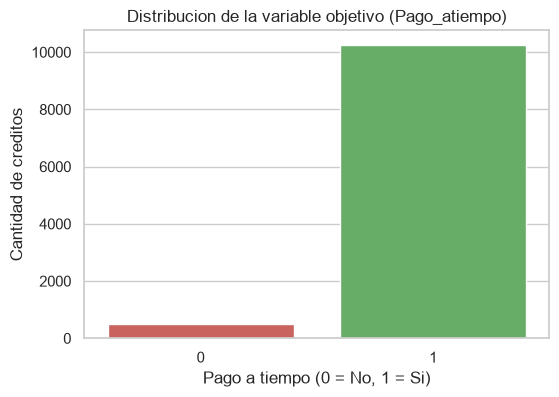

In [22]:
#Visualizo la distribucion de la variable objetivo
conteo_objetivo = dataset['Pago_atiempo'].value_counts()
print(conteo_objetivo)
print()
print((dataset['Pago_atiempo'].value_counts(normalize=True) * 100).round(2))

plt.figure(figsize=(6, 4))
sns.countplot(data=dataset, x='Pago_atiempo', palette=['#d9534f', '#5cb85c'])
plt.title('Distribucion de la variable objetivo (Pago_atiempo)')
plt.xlabel('Pago a tiempo (0 = No, 1 = Si)')
plt.ylabel('Cantidad de creditos')
plt.show()

Variables númericas 

In [23]:
#Visualizo el describe() de las variables numericas ya con los tipos corregidos
dataset[variables_numericas].describe().T

,count,mean,std,min,25%,50%,75%,max
capital_prestado,"10,763.00","2,434,315.00","1,909,642.76","360,000.00","1,224,831.00","1,921,920.00","3,084,840.00","41,444,152.80"
plazo_meses,"10,763.00",10.58,6.63,2.00,6.00,10.00,12.00,90.00
edad_cliente,"10,613.00",42.85,11.95,19.00,33.00,42.00,52.00,69.00
salario_cliente,"10,665.00","4,115,410.95","5,102,723.15","1,000.00","2,000,000.00","3,000,000.00","4,760,000.00","95,985,077.00"
total_otros_prestamos,"10,763.00","6,238,869.65","118,418,316.94",0.00,"500,000.00","1,000,000.00","2,000,000.00","6,787,675,263.00"
cuota_pactada,"10,763.00","243,617.41","210,493.69","23,944.00","121,041.50","182,863.00","287,833.50","3,816,752.00"
puntaje,"10,763.00",91.17,16.47,-38.01,95.23,95.23,95.23,95.23
puntaje_datacredito,"10,611.00",791.53,51.43,7.00,758.00,792.00,826.00,999.00
cant_creditosvigentes,"10,763.00",5.73,3.98,0.00,3.00,5.00,8.00,62.00
huella_consulta,"10,763.00",4.23,3.06,0.00,2.00,4.00,6.00,29.00


In [24]:
#Calculo la descripcion estadistica completa de las variables numericas:
#tendencia central, dispersion, forma de la distribucion y porcentaje de outliers (regla del IQR)
def describir_numericas(df, columnas):
    filas = []
    for col in columnas:
        s = df[col].dropna()
        q1, q3 = s.quantile(0.25), s.quantile(0.75)
        iqr = q3 - q1
        outliers = ((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).mean() * 100
        moda = s.mode().iloc[0]
        filas.append({
            'variable': col, 'nulos': df[col].isnull().sum(),
            'media': s.mean(), 'mediana': s.median(), 'moda': moda,
            'min': s.min(), 'max': s.max(), 'rango': s.max() - s.min(),
            'q1': q1, 'q3': q3, 'IQR': iqr, 'varianza': s.var(), 'desv_std': s.std(),
            'skewness': s.skew(), 'kurtosis': s.kurt(), '%_outliers_IQR': outliers
        })
    return pd.DataFrame(filas).set_index('variable')

descripcion = describir_numericas(dataset, variables_numericas)
descripcion

,nulos,media,mediana,moda,min,max,rango,q1,q3,IQR,varianza,desv_std,skewness,kurtosis,%_outliers_IQR
variable,,,,,,,,,,,,,,,
capital_prestado,0,"2,434,315.00","1,921,920.00","1,200,000.00","360,000.00","41,444,152.80","41,084,152.80","1,224,831.00","3,084,840.00","1,860,009.00","3,646,735,466,988.66","1,909,642.76",3.72,35.32,5.11
plazo_meses,0,10.58,10.00,6.00,2.00,90.00,88.00,6.00,12.00,6.00,43.98,6.63,2.46,7.78,8.07
edad_cliente,150,42.85,42.00,40.00,19.00,69.00,50.00,33.00,52.00,19.00,142.74,11.95,0.27,-0.86,0.00
salario_cliente,98,"4,115,410.95","3,000,000.00","3,000,000.00","1,000.00","95,985,077.00","95,984,077.00","2,000,000.00","4,760,000.00","2,760,000.00","26,037,783,522,052.30","5,102,723.15",8.68,113.16,6.58
total_otros_prestamos,0,"6,238,869.65","1,000,000.00","2,000,000.00",0.00,"6,787,675,263.00","6,787,675,263.00","500,000.00","2,000,000.00","1,500,000.00","14,022,897,787,155,472.00","118,418,316.94",38.46,"1,719.28",5.47
cuota_pactada,0,"243,617.41","182,863.00","205,990.00","23,944.00","3,816,752.00","3,792,808.00","121,041.50","287,833.50","166,792.00","44,307,595,469.58","210,493.69",3.79,26.65,7.11
puntaje,0,91.17,95.23,95.23,-38.01,95.23,133.24,95.23,95.23,0.00,271.11,16.47,-4.87,24.08,12.60
puntaje_datacredito,152,791.53,792.00,783.00,7.00,999.00,992.00,758.00,826.00,68.00,"2,645.35",51.43,-0.99,9.98,0.47
cant_creditosvigentes,0,5.73,5.00,4.00,0.00,62.00,62.00,3.00,8.00,5.00,15.82,3.98,1.80,8.62,2.25


In [25]:
#Clasifico el tipo de distribucion de cada variable segun su skewness y cantidad de valores distintos
def tipo_distribucion(s):
    s = s.dropna()
    sk = s.skew()
    if s.nunique() <= 3:
        return 'Casi constante'
    if sk > 1:
        return 'Asimetrica a la derecha (cola larga, tipo log-normal)'
    if sk < -1:
        return 'Asimetrica a la izquierda'
    if abs(sk) < 0.5:
        return 'Aproximadamente simetrica (gaussiana)'
    return 'Moderadamente asimetrica'

tipos = pd.DataFrame({
    'skewness': [dataset[c].skew() for c in variables_numericas],
    'tipo_de_distribucion': [tipo_distribucion(dataset[c]) for c in variables_numericas]
}, index=variables_numericas)
tipos.sort_values('skewness', ascending=False)

,skewness,tipo_de_distribucion
saldo_mora_codeudor,94.97,"Asimetrica a la derecha (cola larga, tipo log-..."
saldo_mora,40.57,"Asimetrica a la derecha (cola larga, tipo log-..."
total_otros_prestamos,38.46,"Asimetrica a la derecha (cola larga, tipo log-..."
saldo_total,20.20,"Asimetrica a la derecha (cola larga, tipo log-..."
salario_cliente,8.68,"Asimetrica a la derecha (cola larga, tipo log-..."
saldo_principal,5.05,"Asimetrica a la derecha (cola larga, tipo log-..."
promedio_ingresos_datacredito,4.28,"Asimetrica a la derecha (cola larga, tipo log-..."
creditos_sectorCooperativo,4.22,"Asimetrica a la derecha (cola larga, tipo log-..."
cuota_pactada,3.79,"Asimetrica a la derecha (cola larga, tipo log-..."
capital_prestado,3.72,"Asimetrica a la derecha (cola larga, tipo log-..."


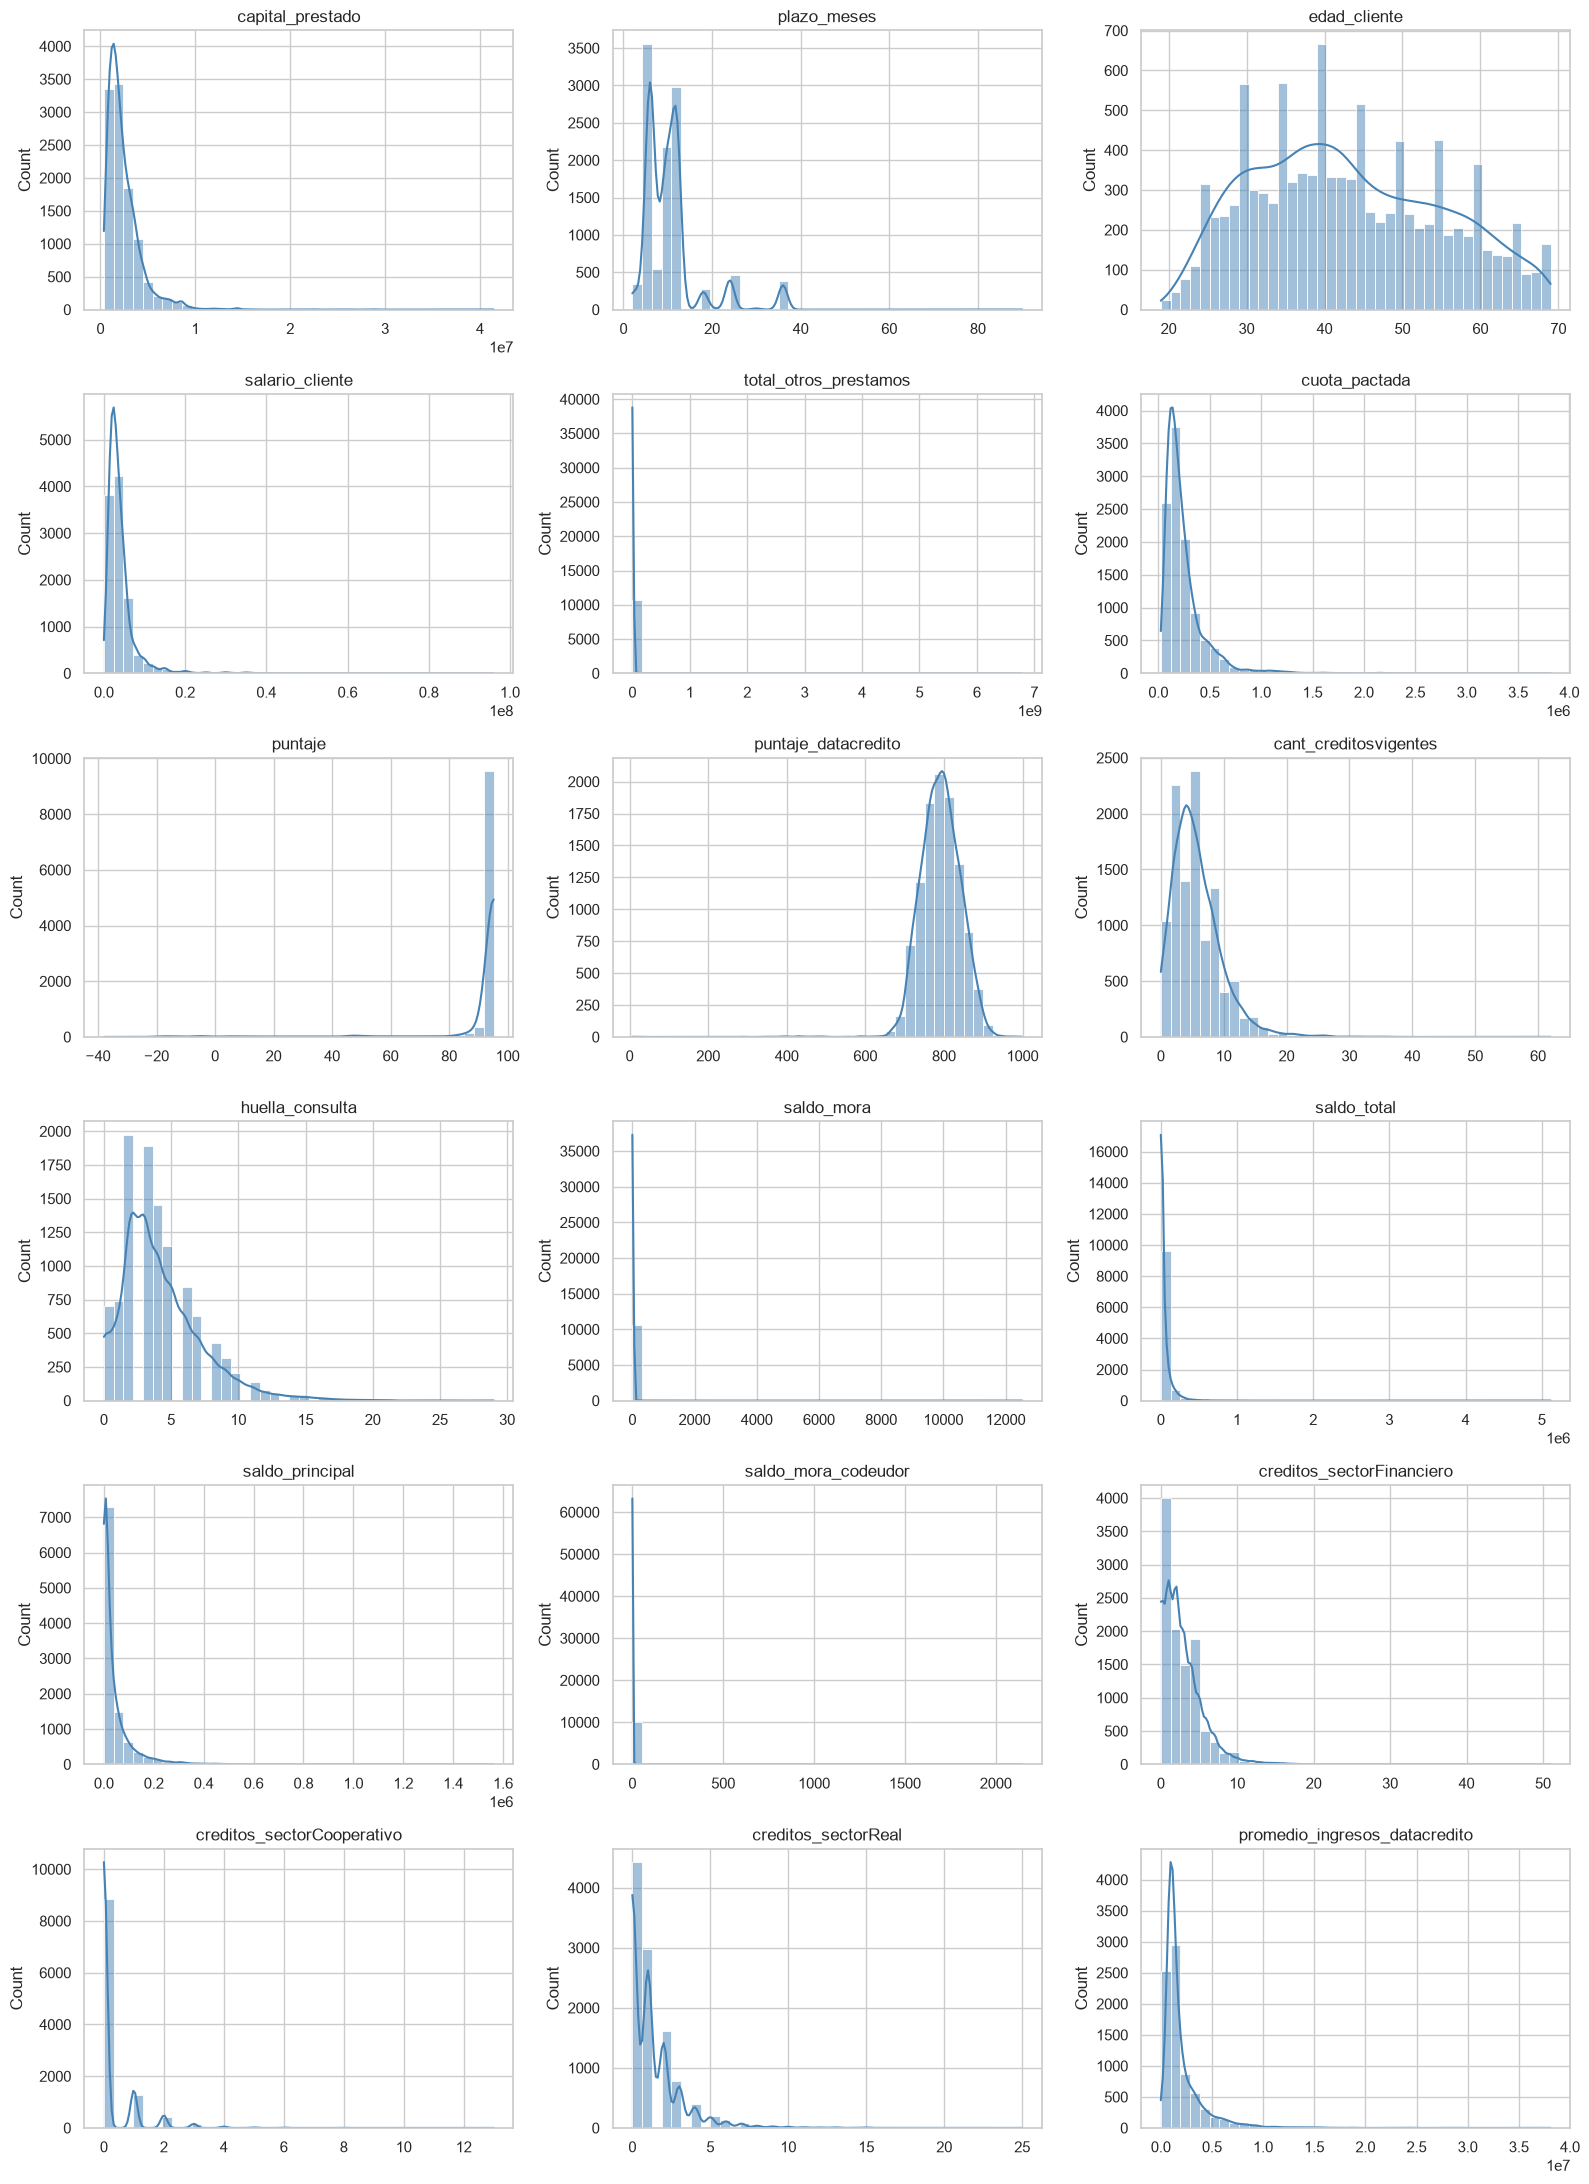

In [26]:
#Histogramas de todas las variables numericas para ver su distribucion
fig, axes = plt.subplots(6, 3, figsize=(16, 22))
for ax, col in zip(axes.flatten(), variables_numericas):
    sns.histplot(dataset[col].dropna(), bins=40, kde=True, ax=ax, color='steelblue')
    ax.set_title(col)
    ax.set_xlabel('')
plt.tight_layout()
plt.show()

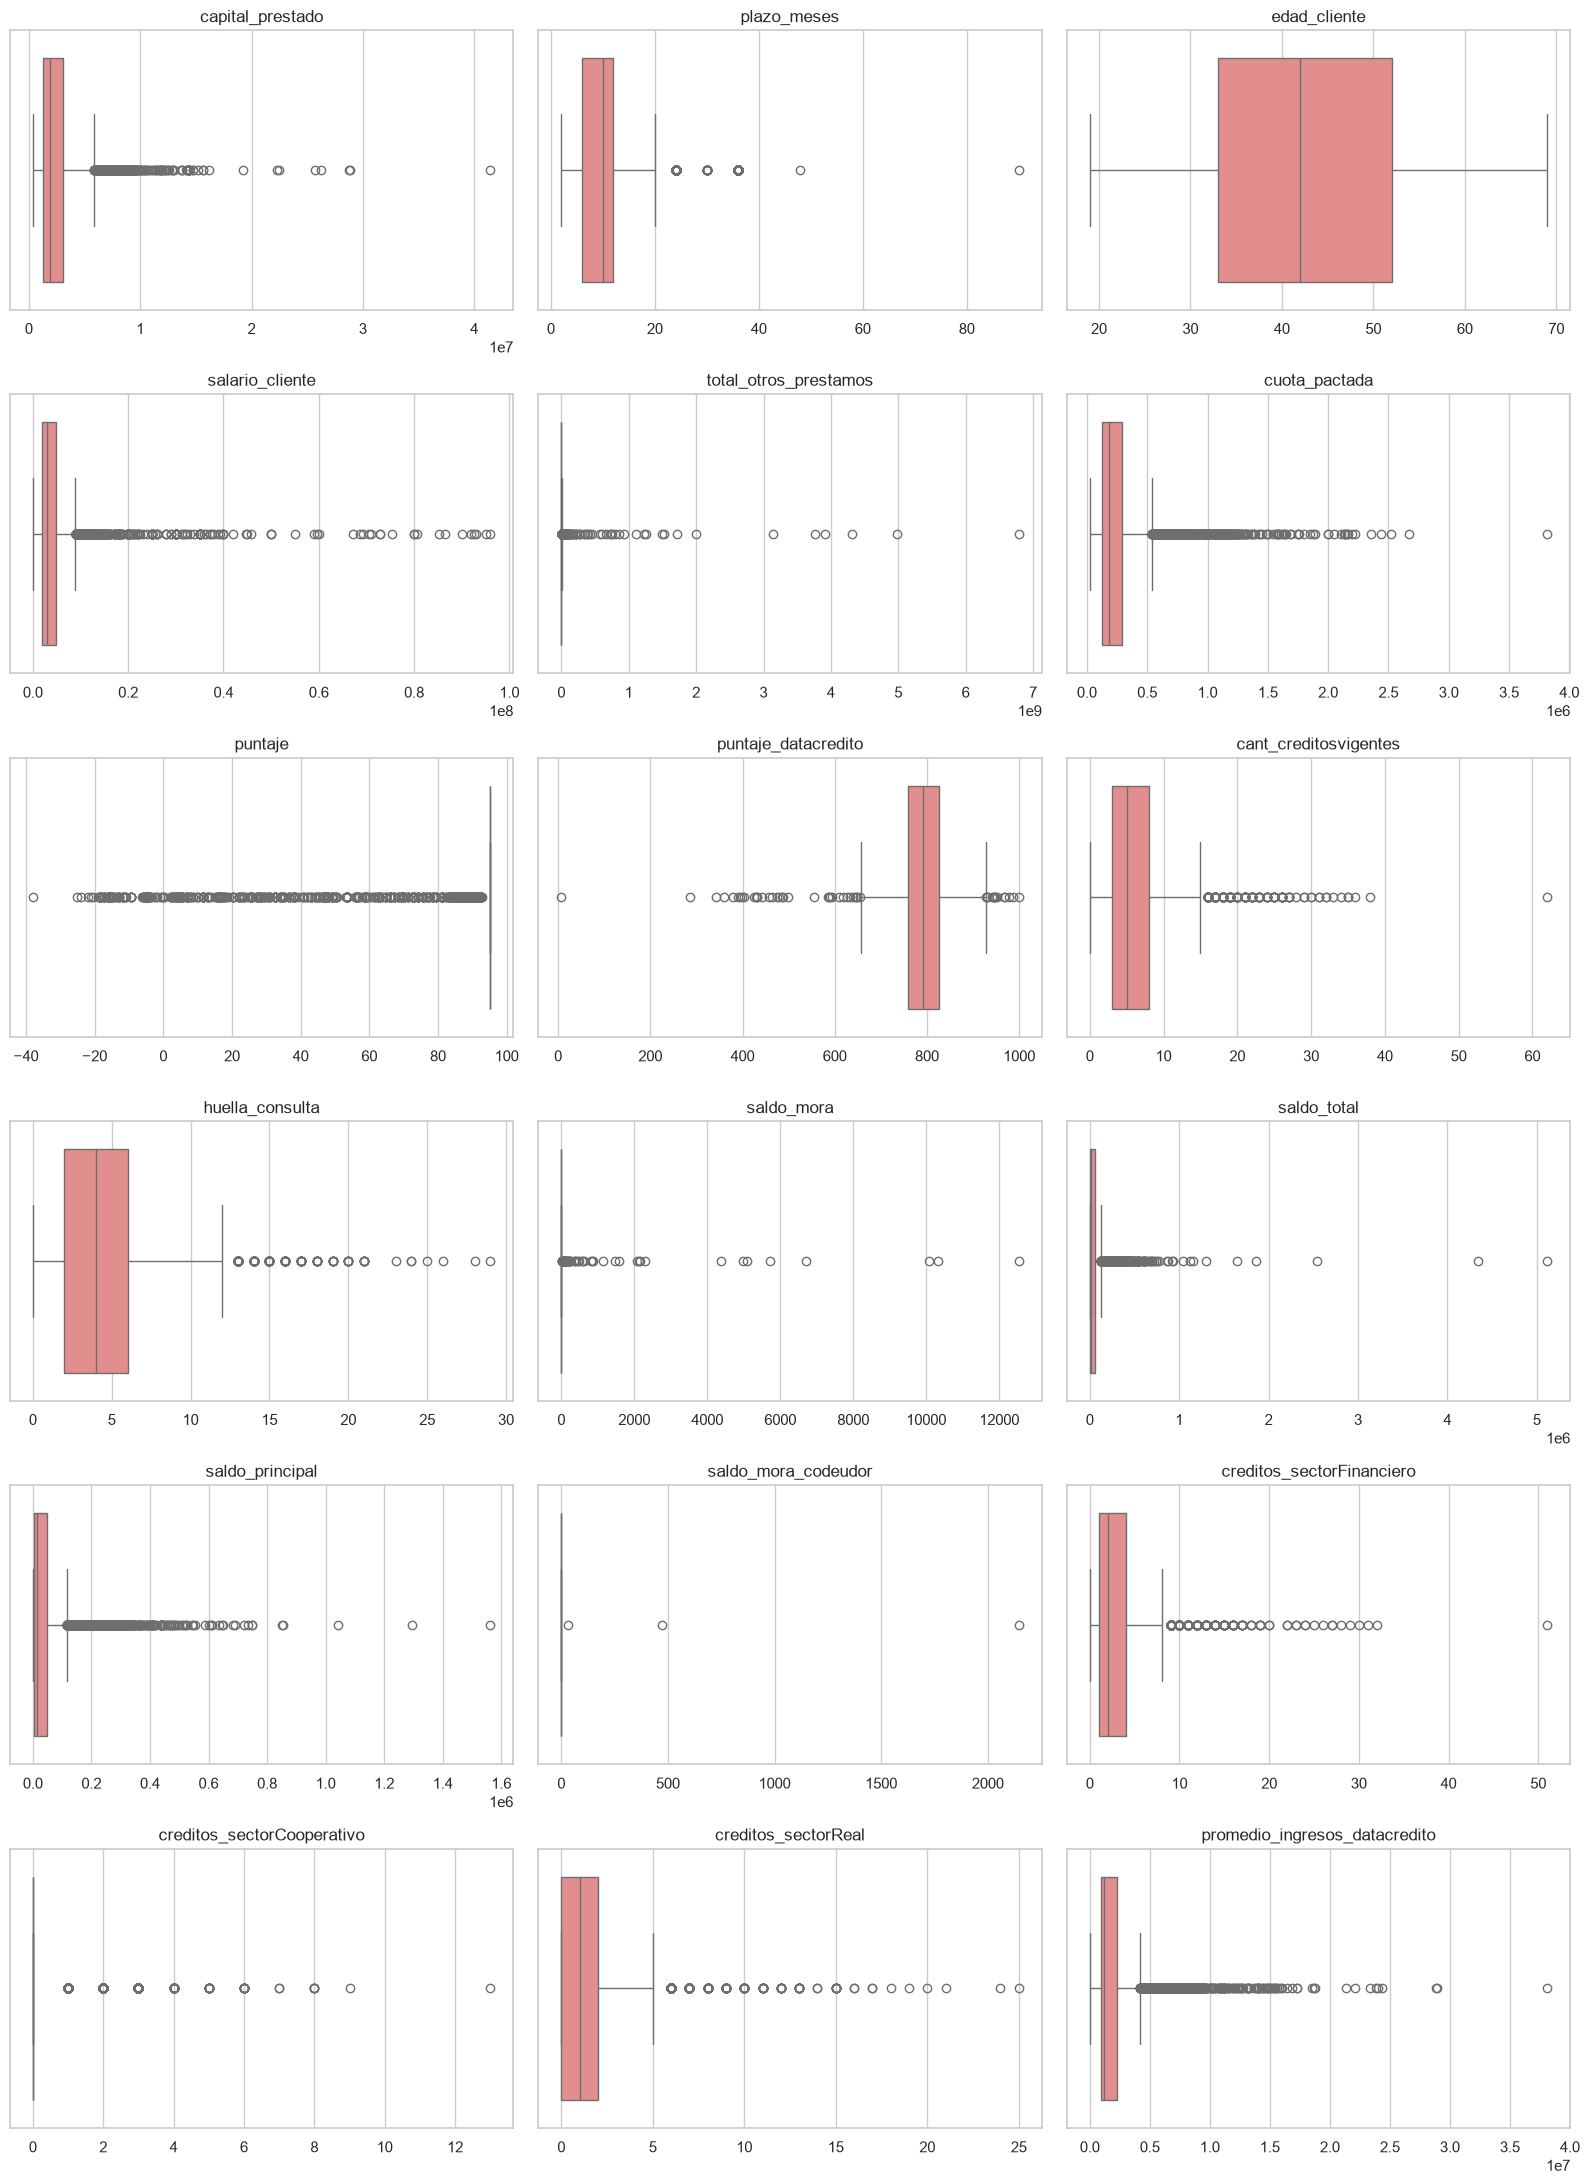

In [27]:
#Boxplots de todas las variables numericas para ver outliers
fig, axes = plt.subplots(6, 3, figsize=(16, 22))
for ax, col in zip(axes.flatten(), variables_numericas):
    sns.boxplot(x=dataset[col].dropna(), ax=ax, color='lightcoral')
    ax.set_title(col)
    ax.set_xlabel('')
plt.tight_layout()
plt.show()

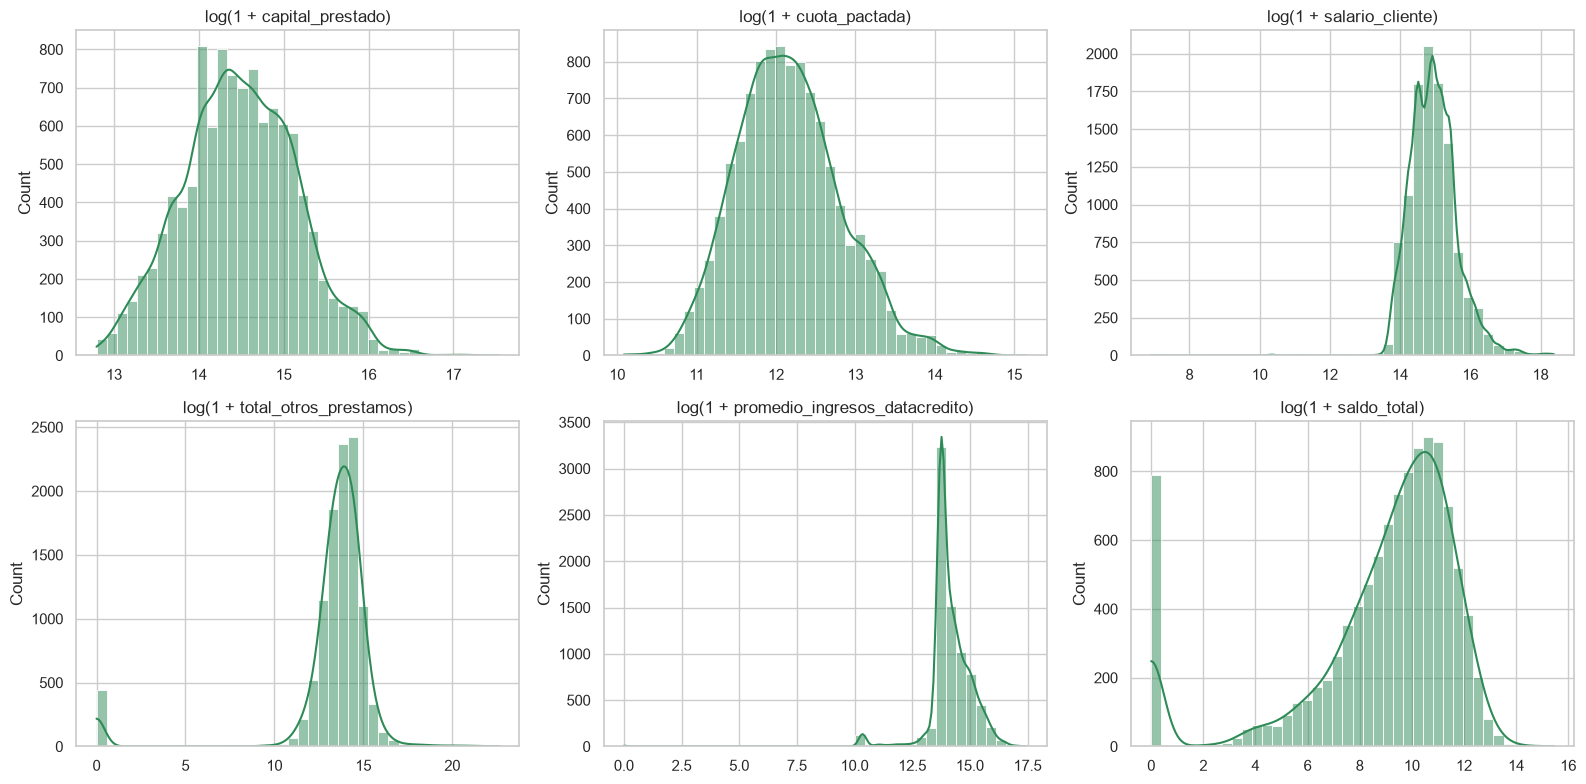

In [28]:
#Las variables de dinero estan muy sesgadas, asi que las visualizo tambien en escala logaritmica
variables_dinero = ['capital_prestado', 'cuota_pactada', 'salario_cliente', 'total_otros_prestamos',
                    'promedio_ingresos_datacredito', 'saldo_total']
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, col in zip(axes.flatten(), variables_dinero):
    sns.histplot(np.log1p(dataset[col].dropna()), bins=40, kde=True, ax=ax, color='seagreen')
    ax.set_title(f'log(1 + {col})')
    ax.set_xlabel('')
plt.tight_layout()
plt.show()

In [29]:
#Cuantos registros tienen puntaje en el maximo?
maximo_puntaje = dataset['puntaje'].max()
print('Valor maximo de puntaje:', round(maximo_puntaje, 4))
print('% de registros con el puntaje maximo:', round((dataset['puntaje'] == maximo_puntaje).mean() * 100, 1))
print('% de registros con saldo_mora > 0:', round((dataset['saldo_mora'] > 0).mean() * 100, 2))

Valor maximo de puntaje: 95.2278
% de registros con el puntaje maximo: 87.4
% de registros con saldo_mora > 0: 0.51


Variables categoricas

In [30]:
#Visualizo la frecuencia de cada categoria (incluyendo nulos)
for col in variables_categoricas:
    print(f'--- {col} ---')
    print(dataset[col].value_counts(dropna=False))
    print()

--- tipo_credito ---
tipo_credito
4     7747
9     2876
10     116
6       21
7        2
68       1
Name: count, dtype: int64

--- tipo_laboral ---
tipo_laboral
Empleado         6754
Independiente    4009
Name: count, dtype: int64

--- tendencia_ingresos ---
tendencia_ingresos
Creciente      5294
NaN            2990
Decreciente    1291
Estable        1188
Name: count, dtype: int64



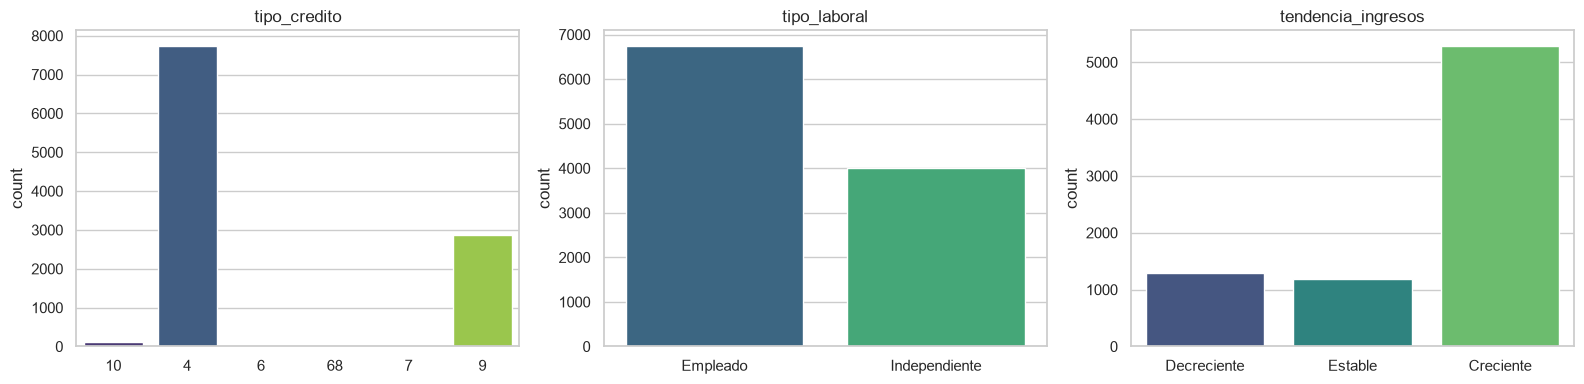

In [31]:
#Countplot de las variables categoricas
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, variables_categoricas):
    sns.countplot(data=dataset, x=col, ax=ax, palette='viridis')
    ax.set_title(col)
    ax.set_xlabel('')
plt.tight_layout()
plt.show()

Fecha del prestamo

Rango de fechas: 2024-11-26 09:17:04 a 2026-04-26 18:43:52


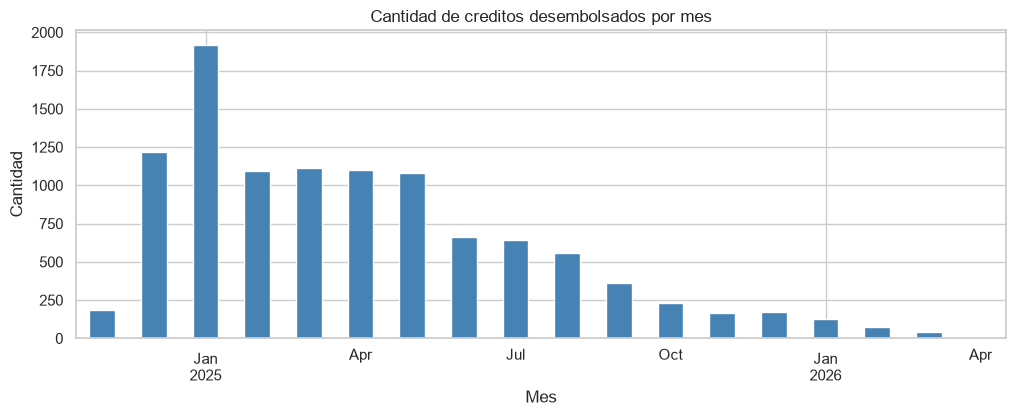

In [32]:
#Cantidad de prestamos por mes
prestamos_por_mes = dataset.groupby(dataset['fecha_prestamo'].dt.to_period('M')).size()
print('Rango de fechas:', dataset['fecha_prestamo'].min(), 'a', dataset['fecha_prestamo'].max())

plt.figure(figsize=(12, 4))
prestamos_por_mes.plot(kind='bar', color='steelblue')
plt.title('Cantidad de creditos desembolsados por mes')
plt.xlabel('Mes')
plt.ylabel('Cantidad')
plt.show()

Analisis bivariable (contra la variable objetivo)

Variables númericas vs pago_atiempo

In [33]:
#Comparo la mediana de cada variable numerica entre quienes pagaron a tiempo y quienes no,
#y aplico la prueba de Mann-Whitney (no asume distribucion normal) para ver si la diferencia es significativa
filas = []
for col in variables_numericas:
    grupo0 = dataset.loc[dataset['Pago_atiempo'] == 0, col].dropna()
    grupo1 = dataset.loc[dataset['Pago_atiempo'] == 1, col].dropna()
    p_valor = stats.mannwhitneyu(grupo0, grupo1).pvalue
    filas.append({'variable': col, 'mediana_no_pago(0)': grupo0.median(), 'mediana_pago(1)': grupo1.median(),
                  'p_valor': p_valor, 'diferencia_significativa': p_valor < 0.05})
comparacion = pd.DataFrame(filas).set_index('variable')
comparacion

,mediana_no_pago(0),mediana_pago(1),p_valor,diferencia_significativa
variable,,,,
capital_prestado,"2,268,000.00","1,908,446.40",0.00,True
plazo_meses,10.00,10.00,0.10,False
edad_cliente,37.00,42.00,0.00,True
salario_cliente,"3,000,000.00","3,000,000.00",0.71,False
total_otros_prestamos,"900,000.00","1,000,000.00",0.01,True
cuota_pactada,"199,002.00","182,576.00",0.13,False
puntaje,25.42,95.23,0.00,True
puntaje_datacredito,769.00,792.00,0.00,True
cant_creditosvigentes,5.00,5.00,0.10,False


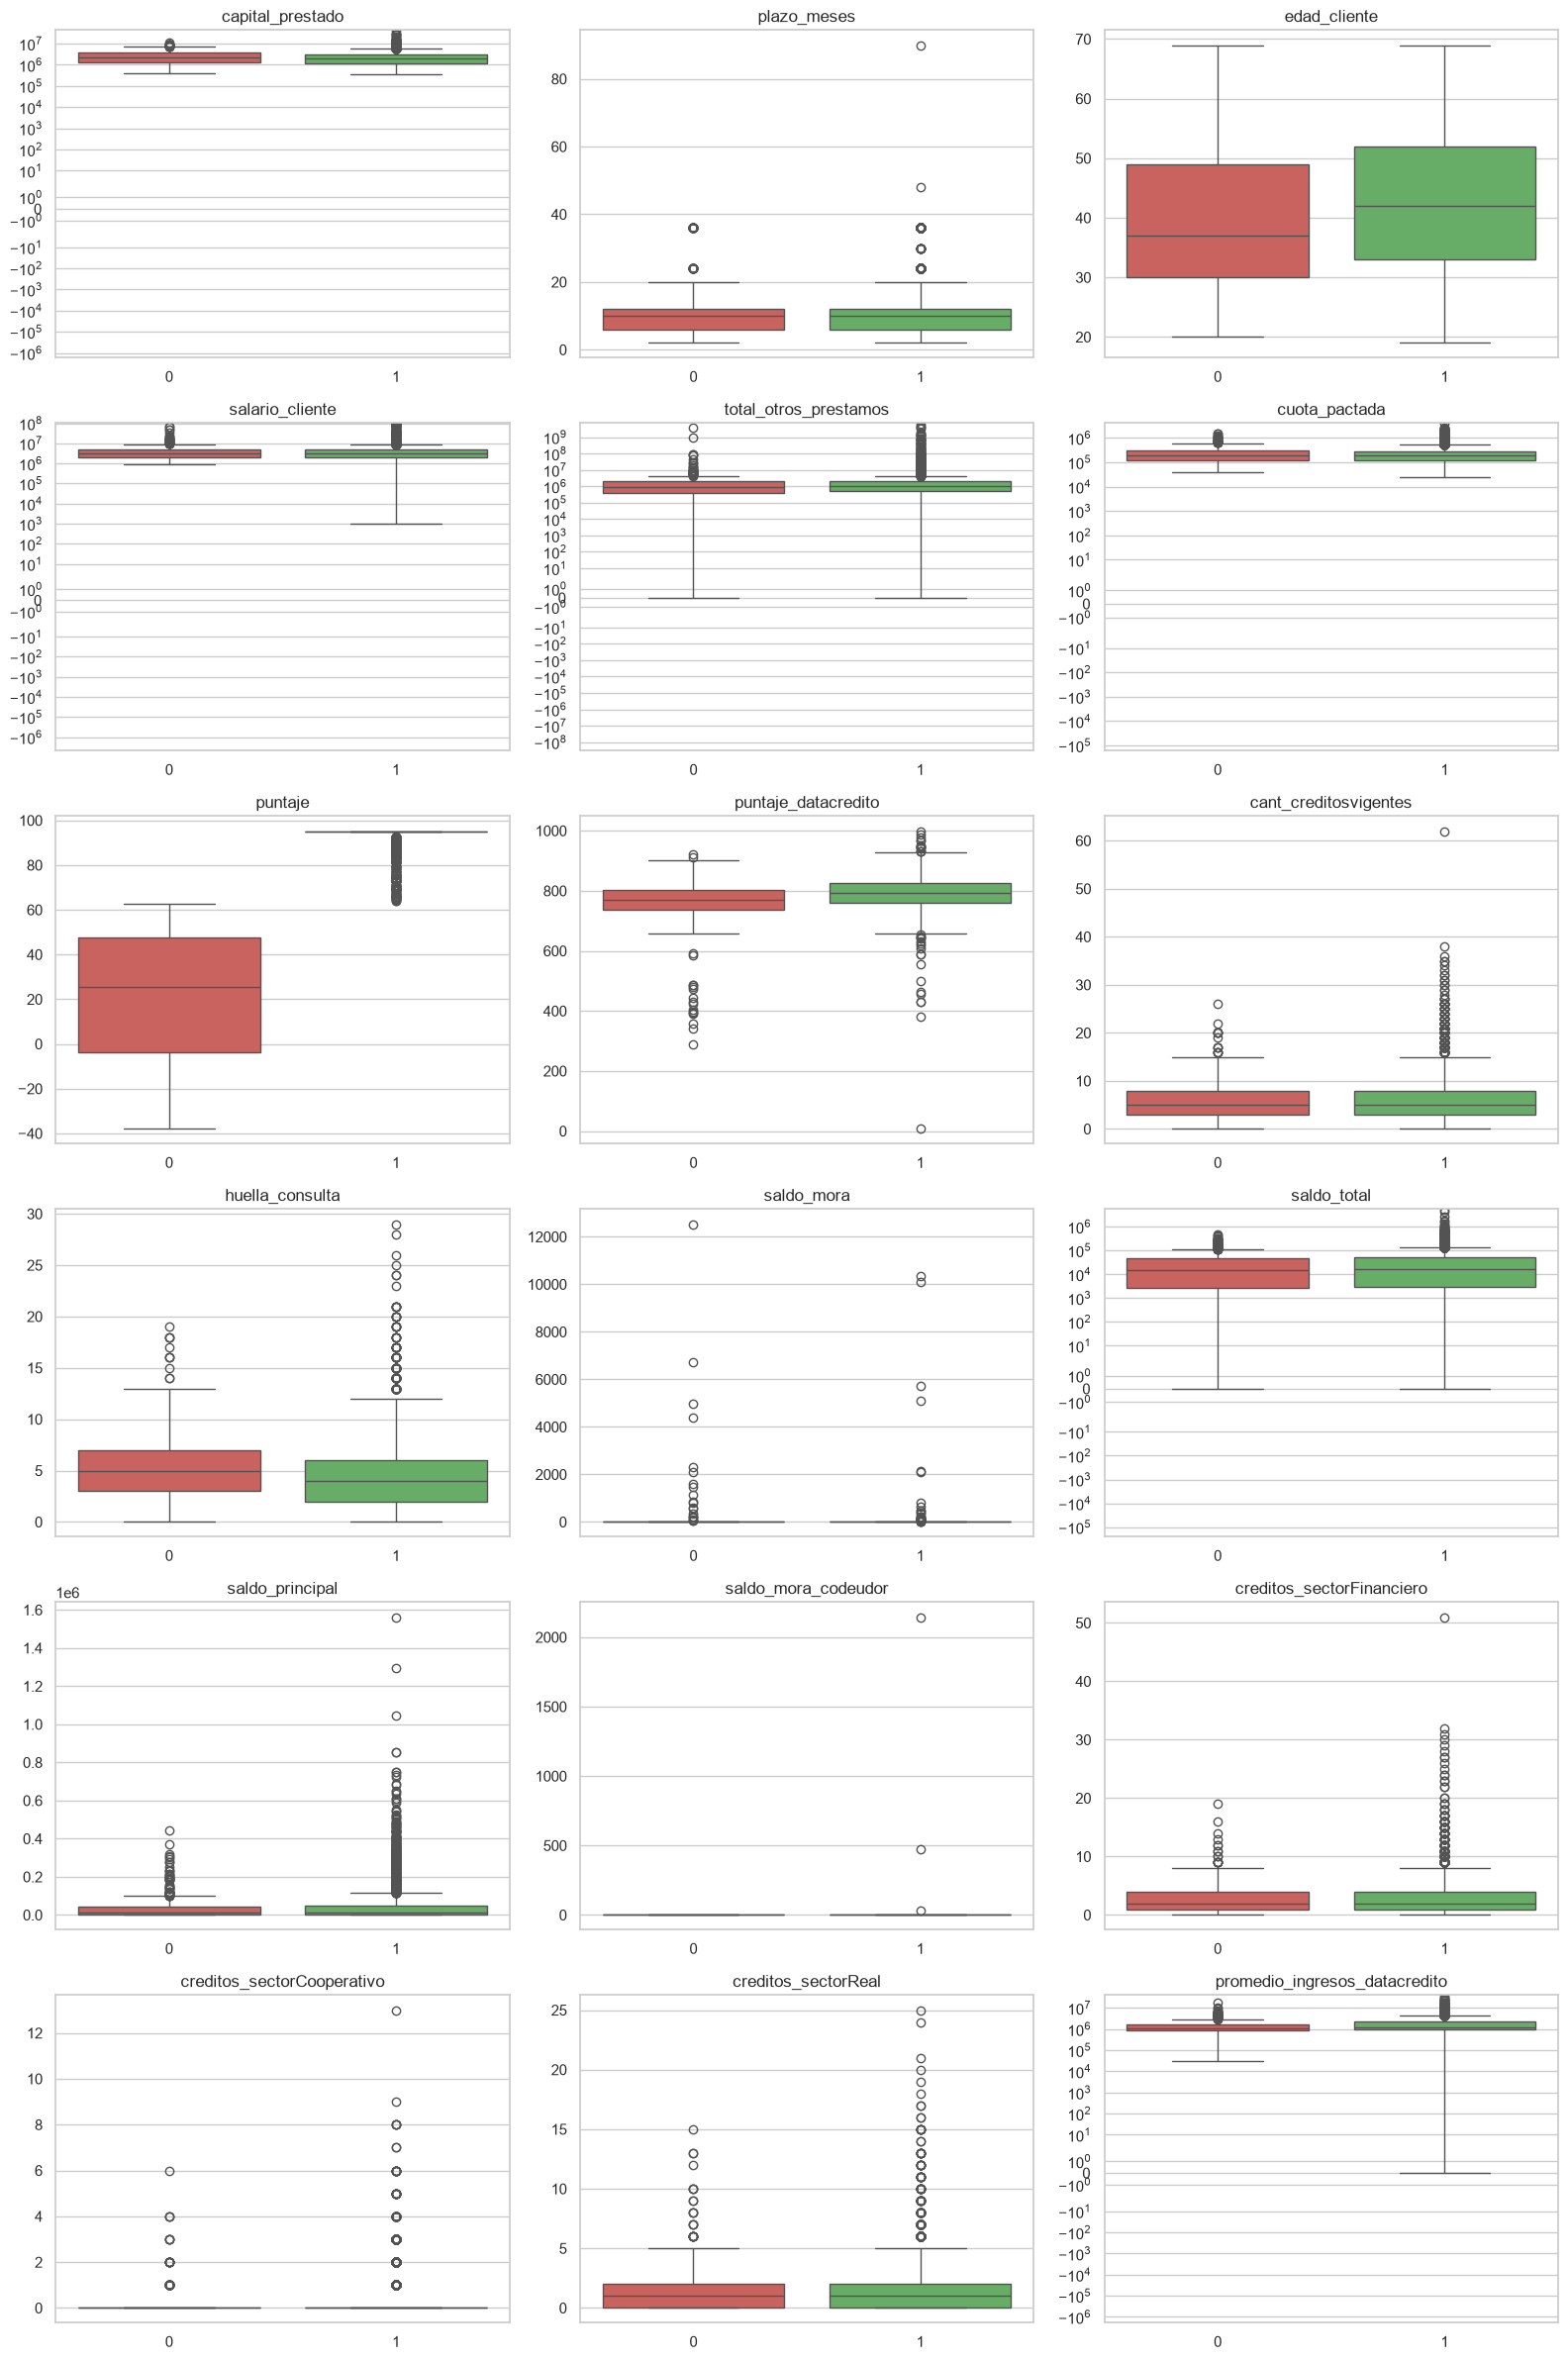

In [34]:
#Boxplots de cada variable numerica separados por la variable objetivo
fig, axes = plt.subplots(6, 3, figsize=(16, 24))
for ax, col in zip(axes.flatten(), variables_numericas):
    sns.boxplot(data=dataset, x='Pago_atiempo', y=col, ax=ax, palette=['#d9534f', '#5cb85c'])
    ax.set_title(col)
    ax.set_xlabel('')
    ax.set_ylabel('')
    if col in variables_dinero:
        ax.set_yscale('symlog')
plt.tight_layout()
plt.show()

Variable sospechosa: puntaje

In [35]:
#Reviso el rango de puntaje en cada grupo del objetivo
dataset.groupby('Pago_atiempo')['puntaje'].describe()

,count,mean,std,min,25%,50%,75%,max
Pago_atiempo,,,,,,,,
0,511.00,23.09,26.07,-38.01,-3.59,25.42,47.61,62.67
1,"10,252.00",94.56,2.87,63.81,95.23,95.23,95.23,95.23


Maximo puntaje de quienes NO pagaron a tiempo: 62.67
Minimo puntaje de quienes SI pagaron a tiempo: 63.81
Los grupos se separan perfectamente con un umbral: True
Correlacion de puntaje con el objetivo: 0.923


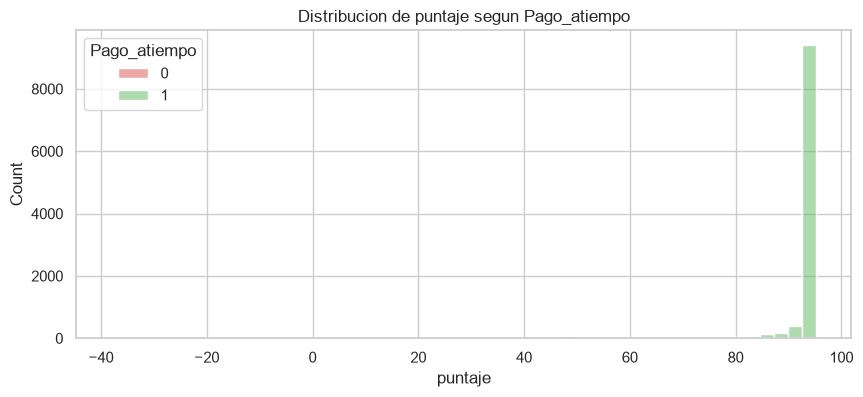

In [36]:
#Verifico si los rangos de puntaje se solapan entre los dos grupos
max_no_pago = dataset.loc[dataset['Pago_atiempo'] == 0, 'puntaje'].max()
min_pago = dataset.loc[dataset['Pago_atiempo'] == 1, 'puntaje'].min()
print(f'Maximo puntaje de quienes NO pagaron a tiempo: {max_no_pago:.2f}')
print(f'Minimo puntaje de quienes SI pagaron a tiempo: {min_pago:.2f}')
print('Los grupos se separan perfectamente con un umbral:', max_no_pago < min_pago)
print('Correlacion de puntaje con el objetivo:', round(dataset['puntaje'].corr(dataset['Pago_atiempo']), 3))

plt.figure(figsize=(10, 4))
sns.histplot(data=dataset, x='puntaje', hue='Pago_atiempo', bins=50, palette=['#d9534f', '#5cb85c'])
plt.title('Distribucion de puntaje segun Pago_atiempo')
plt.show()

Variables categoricas vs pago_atiempo

In [37]:
#Tasa de pago a tiempo y cantidad de creditos por cada categoria
for col in variables_categoricas:
    tabla = dataset.groupby(col, dropna=False)['Pago_atiempo'].agg(['count', 'mean'])
    tabla.columns = ['cantidad', 'tasa_pago_atiempo']
    tabla['tasa_pago_atiempo'] = tabla['tasa_pago_atiempo'] * 100
    print(f'--- {col} ---')
    print(tabla)
    print()

--- tipo_credito ---
              cantidad  tasa_pago_atiempo
tipo_credito                             
10                 116              97.41
4                 7747              95.31
6                   21              57.14
68                   1             100.00
7                    2             100.00
9                 2876              95.27

--- tipo_laboral ---
               cantidad  tasa_pago_atiempo
tipo_laboral                              
Empleado           6754              95.71
Independiente      4009              94.49

--- tendencia_ingresos ---
                    cantidad  tasa_pago_atiempo
tendencia_ingresos                             
Decreciente             1291              93.73
Estable                 1188              95.37
Creciente               5294              96.09
NaN                     2990              94.38



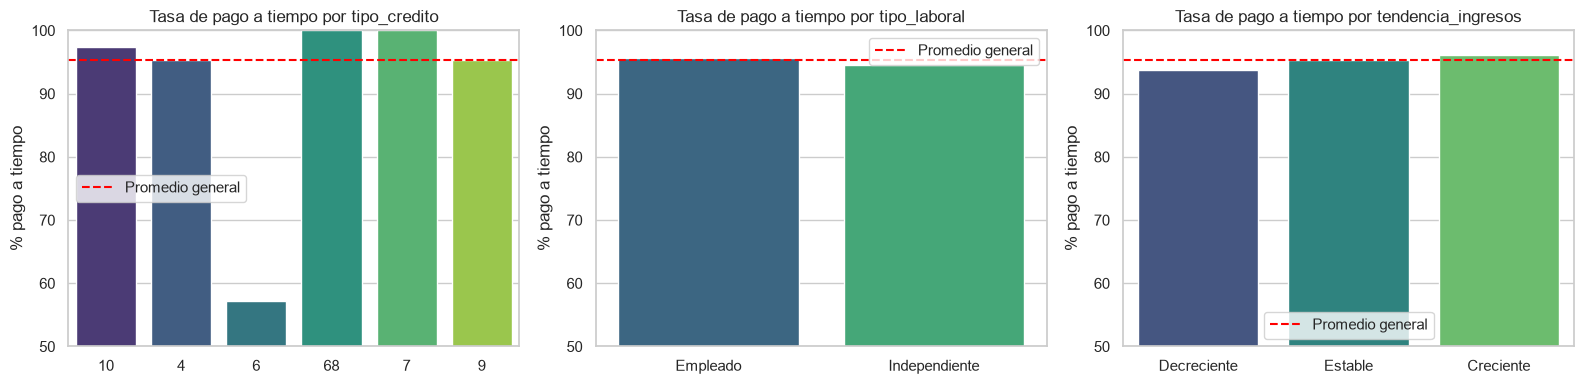

In [38]:
#Grafico de la tasa de pago a tiempo por categoria
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, variables_categoricas):
    tasa = dataset.groupby(col, dropna=False)['Pago_atiempo'].mean() * 100
    tasa.index = tasa.index.astype(str)
    sns.barplot(x=tasa.index, y=tasa.values, ax=ax, palette='viridis')
    ax.axhline(dataset['Pago_atiempo'].mean() * 100, color='red', linestyle='--', label='Promedio general')
    ax.set_ylim(50, 100)
    ax.set_title(f'Tasa de pago a tiempo por {col}')
    ax.set_ylabel('% pago a tiempo')
    ax.set_xlabel('')
    ax.legend()
plt.tight_layout()
plt.show()

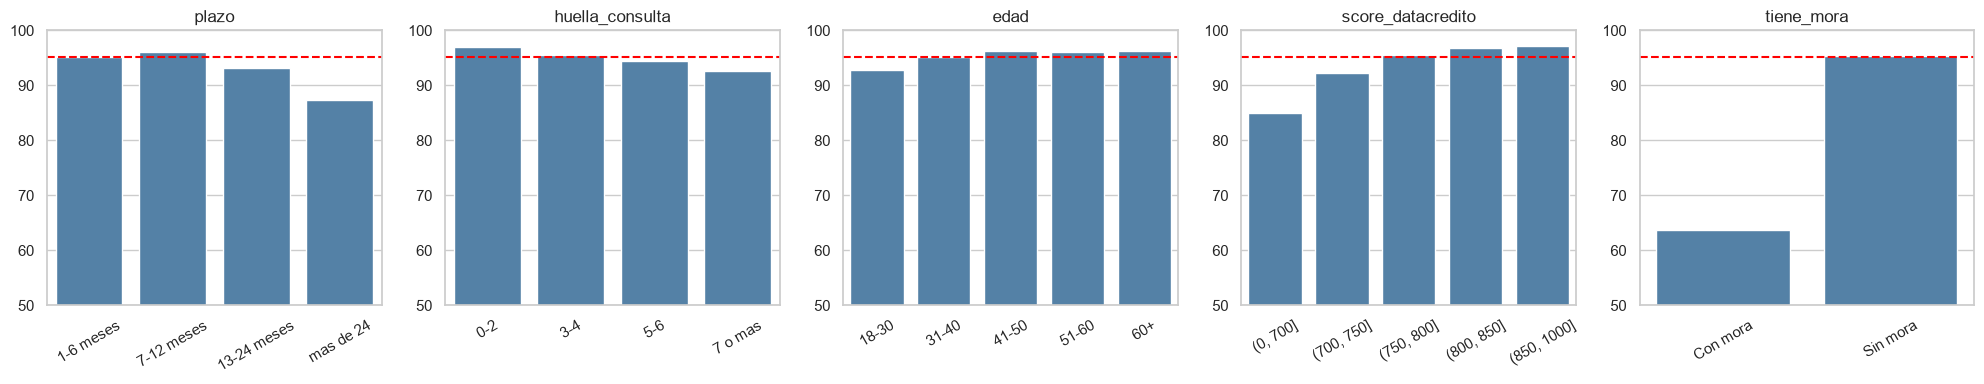

In [39]:
#Creo rangos de algunas variables para ver como cambia la tasa de pago a tiempo
rangos = pd.DataFrame({
    'plazo': pd.cut(dataset['plazo_meses'], bins=[0, 6, 12, 24, 100], labels=['1-6 meses', '7-12 meses', '13-24 meses', 'mas de 24']),
    'huella_consulta': pd.cut(dataset['huella_consulta'], bins=[-1, 2, 4, 6, 100], labels=['0-2', '3-4', '5-6', '7 o mas']),
    'edad': pd.cut(dataset['edad_cliente'], bins=[17, 30, 40, 50, 60, 100], labels=['18-30', '31-40', '41-50', '51-60', '60+']),
    'score_datacredito': pd.cut(dataset['puntaje_datacredito'], bins=[0, 700, 750, 800, 850, 1000]),
    'tiene_mora': np.where(dataset['saldo_mora'] > 0, 'Con mora', 'Sin mora')
})
fig, axes = plt.subplots(1, 5, figsize=(20, 4))
for ax, col in zip(axes, rangos.columns):
    tasa = dataset.groupby(rangos[col])['Pago_atiempo'].mean() * 100
    sns.barplot(x=tasa.index.astype(str), y=tasa.values, ax=ax, color='steelblue')
    ax.axhline(dataset['Pago_atiempo'].mean() * 100, color='red', linestyle='--')
    ax.set_ylim(50, 100)
    ax.set_title(col)
    ax.set_xlabel('')
    ax.tick_params(axis='x', rotation=30)
plt.tight_layout()
plt.show()

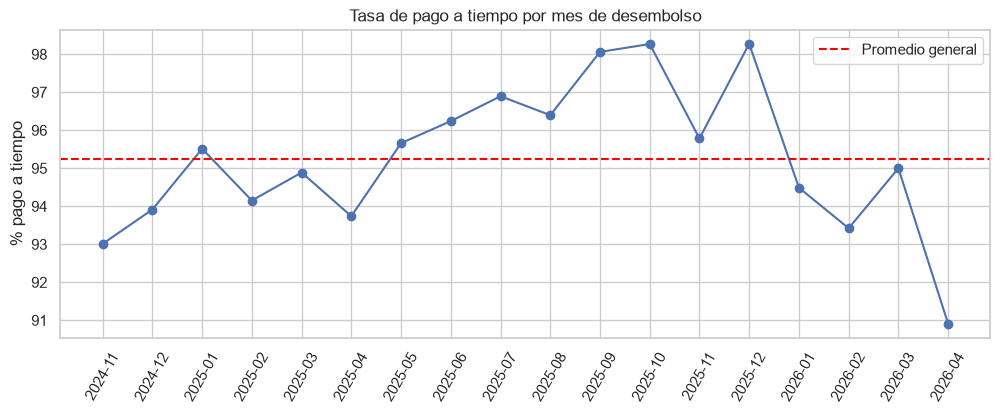

In [40]:
#Tasa de pago a tiempo segun el mes del prestamo
tasa_mensual = dataset.groupby(dataset['fecha_prestamo'].dt.to_period('M'))['Pago_atiempo'].agg(['count', 'mean'])
tasa_mensual.columns = ['cantidad', 'tasa_pago_atiempo']

plt.figure(figsize=(12, 4))
plt.plot(tasa_mensual.index.astype(str), tasa_mensual['tasa_pago_atiempo'] * 100, marker='o')
plt.axhline(dataset['Pago_atiempo'].mean() * 100, color='red', linestyle='--', label='Promedio general')
plt.title('Tasa de pago a tiempo por mes de desembolso')
plt.xticks(rotation=60)
plt.ylabel('% pago a tiempo')
plt.legend()
plt.show()

Analisis multivariable

Matriz de correlación

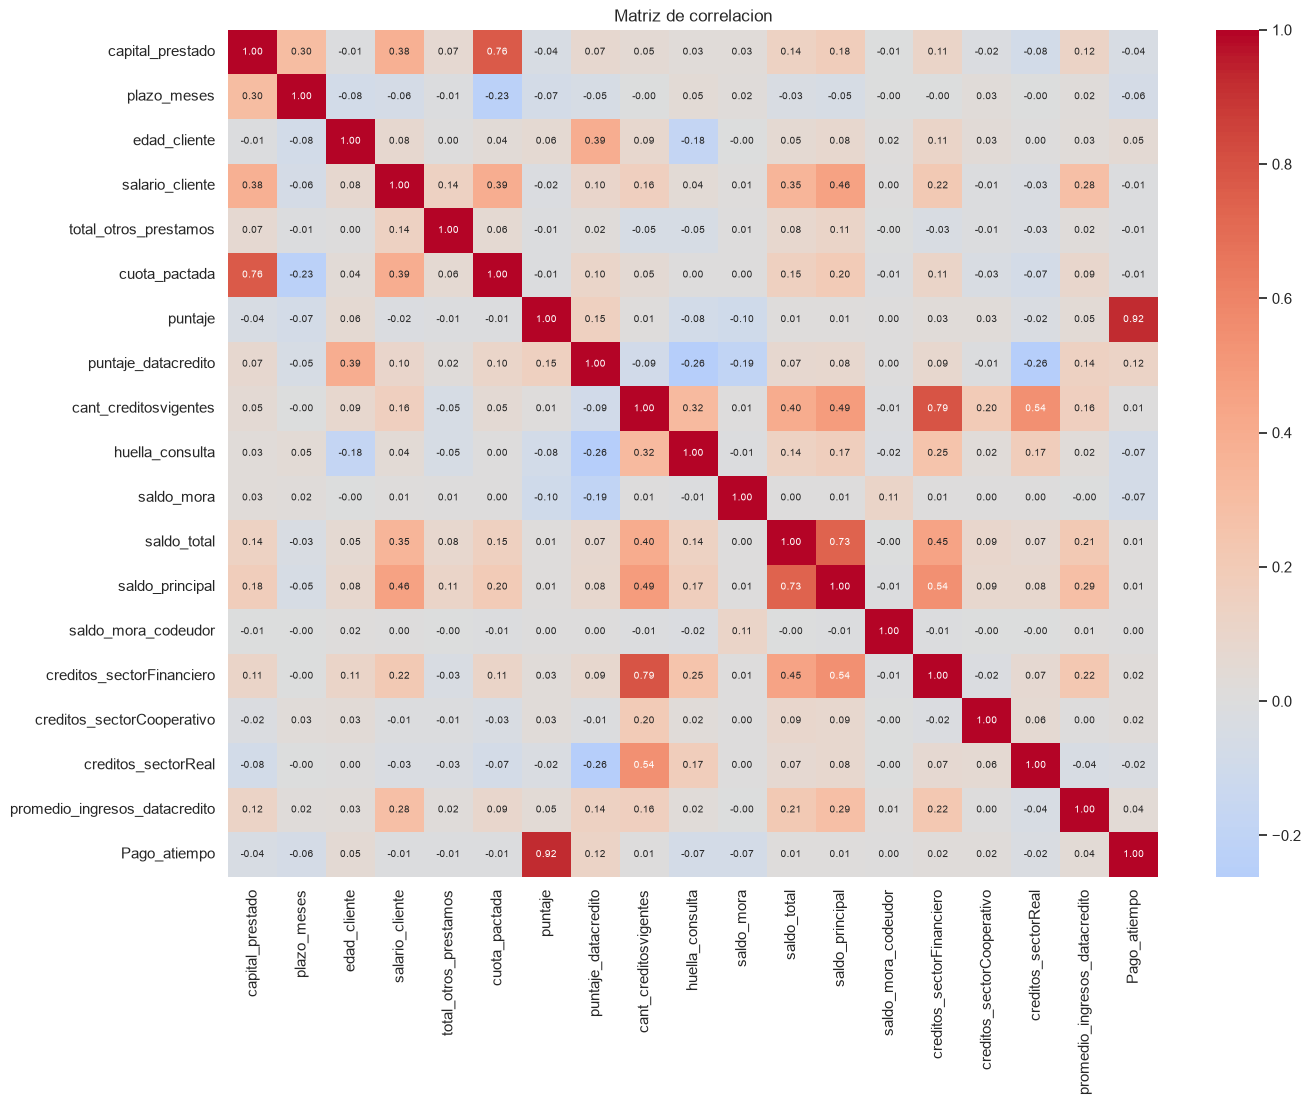

In [41]:
#Matriz de correlacion entre las variables numericas y el objetivo
variables_corr = variables_numericas + ['Pago_atiempo']
matriz_corr = dataset[variables_corr].corr()

plt.figure(figsize=(15, 11))
sns.heatmap(matriz_corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, annot_kws={'size': 7})
plt.title('Matriz de correlacion')
plt.show()

In [42]:
#Parejas de variables con correlacion alta (mayor a 0.7 en valor absoluto)
corr_sin_diagonal = matriz_corr.where(np.triu(np.ones(matriz_corr.shape), k=1).astype(bool)).stack()
corr_alta = corr_sin_diagonal[corr_sin_diagonal.abs() > 0.7].sort_values(ascending=False)
corr_alta.to_frame('correlacion')

,,correlacion
puntaje,Pago_atiempo,0.92
cant_creditosvigentes,creditos_sectorFinanciero,0.79
capital_prestado,cuota_pactada,0.76
saldo_total,saldo_principal,0.73


In [43]:
#Correlacion de cada variable con el objetivo
matriz_corr['Pago_atiempo'].drop('Pago_atiempo').sort_values(ascending=False).to_frame('correlacion_con_objetivo')

,correlacion_con_objetivo
puntaje,0.92
puntaje_datacredito,0.12
edad_cliente,0.05
promedio_ingresos_datacredito,0.04
creditos_sectorFinanciero,0.02
creditos_sectorCooperativo,0.02
saldo_total,0.01
saldo_principal,0.01
cant_creditosvigentes,0.01
saldo_mora_codeudor,0.00


Graficos de dispersión y pairplot

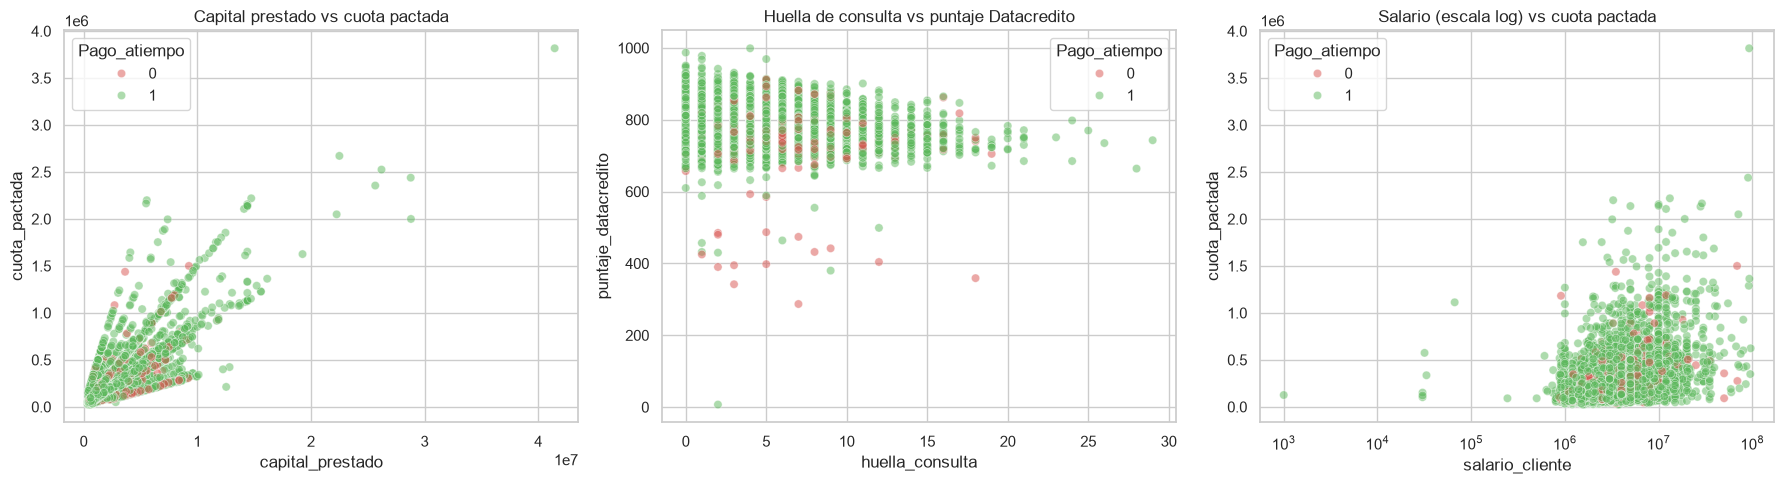

In [44]:
#Dispersion entre variables numericas importantes, coloreando por la variable objetivo
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.scatterplot(data=dataset, x='capital_prestado', y='cuota_pactada', hue='Pago_atiempo',
                palette=['#d9534f', '#5cb85c'], alpha=0.5, ax=axes[0])
axes[0].set_title('Capital prestado vs cuota pactada')

sns.scatterplot(data=dataset, x='huella_consulta', y='puntaje_datacredito', hue='Pago_atiempo',
                palette=['#d9534f', '#5cb85c'], alpha=0.5, ax=axes[1])
axes[1].set_title('Huella de consulta vs puntaje Datacredito')

sns.scatterplot(data=dataset, x='salario_cliente', y='cuota_pactada', hue='Pago_atiempo',
                palette=['#d9534f', '#5cb85c'], alpha=0.5, ax=axes[2])
axes[2].set_xscale('log')
axes[2].set_title('Salario (escala log) vs cuota pactada')

plt.tight_layout()
plt.show()

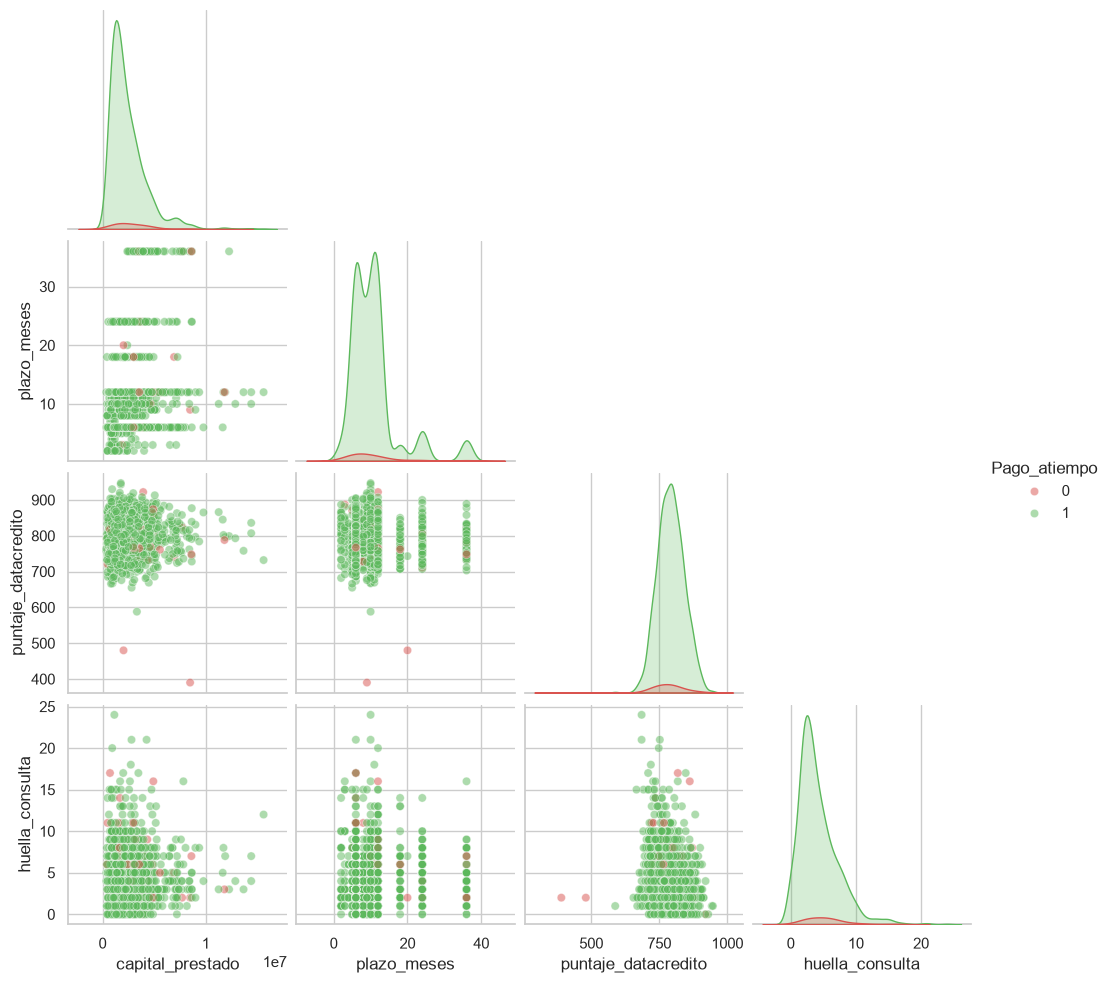

In [45]:
#Pairplot de las variables numericas mas relevantes (uso una muestra para que no sea lento)
columnas_pairplot = ['capital_prestado', 'plazo_meses', 'puntaje_datacredito', 'huella_consulta', 'Pago_atiempo']
muestra = dataset[columnas_pairplot].dropna().sample(1500, random_state=42)
sns.pairplot(muestra, hue='Pago_atiempo', palette=['#d9534f', '#5cb85c'], plot_kws={'alpha': 0.5}, corner=True)
plt.show()

Tablas cruzadas y variables categoricas

In [46]:
#Tabla cruzada entre tipo laboral y tendencia de ingresos (cantidad de creditos)
pd.crosstab(dataset['tipo_laboral'], dataset['tendencia_ingresos'], dropna=False, margins=True)

tendencia_ingresos,Decreciente,Estable,Creciente,All
tipo_laboral,,,,
Empleado,937,646,3843,6754
Independiente,354,542,1451,4009
All,1291,1188,5294,10763


In [47]:
#Tasa de pago a tiempo (%) segun tipo laboral y tendencia de ingresos
pd.pivot_table(dataset, values='Pago_atiempo', index='tipo_laboral', columns='tendencia_ingresos',
               aggfunc='mean', observed=False).mul(100).round(1)

tendencia_ingresos,Decreciente,Estable,Creciente
tipo_laboral,,,
Empleado,94.10,95.50,96.40
Independiente,92.70,95.20,95.20


In [48]:
#Tasa de pago a tiempo (%) segun tipo de credito y tipo laboral
pd.pivot_table(dataset, values='Pago_atiempo', index='tipo_credito', columns='tipo_laboral',
               aggfunc=['mean', 'count'], observed=False).round(3)

mean                  count              
tipo_laboral Empleado Independiente Empleado Independiente
tipo_credito                                              
10               0.97          0.98       75            41
4                0.96          0.94     5052          2695
6                0.57           NaN       21             0
68               1.00           NaN        1             0
7                1.00          1.00        1             1
9                0.96          0.95     1604          1272

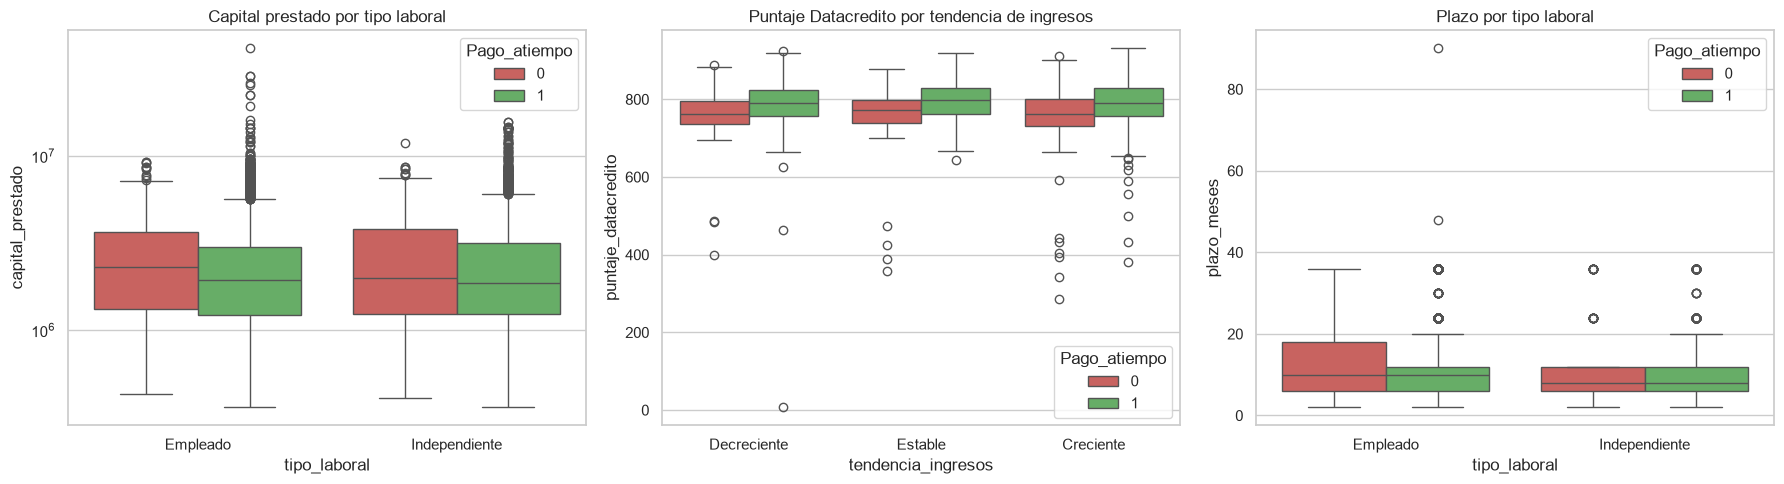

In [49]:
#Boxplots usando el parametro hue para combinar una variable categorica con el objetivo
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
sns.boxplot(data=dataset, x='tipo_laboral', y='capital_prestado', hue='Pago_atiempo', palette=['#d9534f', '#5cb85c'], ax=axes[0])
axes[0].set_yscale('log')
axes[0].set_title('Capital prestado por tipo laboral')
sns.boxplot(data=dataset, x='tendencia_ingresos', y='puntaje_datacredito', hue='Pago_atiempo', palette=['#d9534f', '#5cb85c'], ax=axes[1])
axes[1].set_title('Puntaje Datacredito por tendencia de ingresos')
sns.boxplot(data=dataset, x='tipo_laboral', y='plazo_meses', hue='Pago_atiempo', palette=['#d9534f', '#5cb85c'], ax=axes[2])
axes[2].set_title('Plazo por tipo laboral')
plt.tight_layout()
plt.show()

Reglas de validación

In [50]:
#Aplico las reglas de validacion sobre los datos originales y cuento cuantos registros las incumplen
d = dataset_original
salario_valido = (d['salario_cliente'] > 0) & (d['salario_cliente'] <= 100_000_000)

reglas = {
    '1. edad_cliente fuera de 18-100': ~d['edad_cliente'].between(18, 100),
    '2. salario_cliente fuera de (0, 100 millones]': ~salario_valido,
    '3. capital_prestado o cuota_pactada <= 0': (d['capital_prestado'] <= 0) | (d['cuota_pactada'] <= 0),
    '4. plazo_meses fuera de 1-60': ~d['plazo_meses'].between(1, 60),
    '5. puntaje_datacredito fuera de 1-950': d['puntaje_datacredito'].notna() & ~d['puntaje_datacredito'].between(1, 950),
    '6. tendencia_ingresos con valor invalido': d['tendencia_ingresos'].notna() & ~d['tendencia_ingresos'].isin(['Creciente', 'Estable', 'Decreciente']),
    '7. Pago_atiempo distinto de 0/1': ~d['Pago_atiempo'].isin([0, 1]),
    '8. algun saldo negativo': (d[['saldo_mora', 'saldo_total', 'saldo_principal']] < 0).any(axis=1),
    '9. saldo_mora o saldo_principal > saldo_total': (d['saldo_mora'] > d['saldo_total']) | (d['saldo_principal'] > d['saldo_total']),
    '10. saldo_principal nulo con creditos vigentes > 0': d['saldo_principal'].isna() & (d['cant_creditosvigentes'] > 0),
    '11. cuota_pactada > salario (salario valido)': salario_valido & (d['cuota_pactada'] > d['salario_cliente']),
    '12. fecha_prestamo futura': d['fecha_prestamo'] > pd.Timestamp.today(),
    '13. tipo_credito fuera del catalogo': ~d['tipo_credito'].isin([4, 9, 10, 6, 7, 68]),
    '14. tipo_laboral invalido': ~d['tipo_laboral'].isin(['Empleado', 'Independiente']),
}

resultado_reglas = pd.DataFrame({
    'registros_que_incumplen': {nombre: int(mask.sum()) for nombre, mask in reglas.items()}
})
resultado_reglas['porcentaje'] = resultado_reglas['registros_que_incumplen'] / len(d) * 100
resultado_reglas

,registros_que_incumplen,porcentaje
1. edad_cliente fuera de 18-100,150,1.39
"2. salario_cliente fuera de (0, 100 millones]",98,0.91
3. capital_prestado o cuota_pactada <= 0,0,0.00
4. plazo_meses fuera de 1-60,1,0.01
5. puntaje_datacredito fuera de 1-950,152,1.41
6. tendencia_ingresos con valor invalido,58,0.54
7. Pago_atiempo distinto de 0/1,0,0.00
8. algun saldo negativo,0,0.00
9. saldo_mora o saldo_principal > saldo_total,0,0.00
10. saldo_principal nulo con creditos vigentes > 0,0,0.00


In [51]:
#Reviso las relaciones entre variables que parecen raras y habria que confirmar con el negocio
costo_total_vs_capital = (dataset['cuota_pactada'] * dataset['plazo_meses']) / dataset['capital_prestado']
print('Relacion (cuota x plazo) / capital:')
print(costo_total_vs_capital.describe())
print()
suma_sectores = dataset[['creditos_sectorFinanciero', 'creditos_sectorCooperativo', 'creditos_sectorReal']].sum(axis=1)
print('Diferencia entre la suma de creditos por sector y cant_creditosvigentes:')
print((suma_sectores - dataset['cant_creditosvigentes']).describe())

Relacion (cuota x plazo) / capital:
count   10,763.00
mean         0.91
std          0.09
min          0.79
25%          0.85
50%          0.89
75%          0.94
max          1.52
dtype: float64

Diferencia entre la suma de creditos por sector y cant_creditosvigentes:
count   10,763.00
mean        -1.37
std          1.31
min        -12.00
25%         -2.00
50%         -1.00
75%          0.00
max          2.00
dtype: float64


Atributos adicionales que pueden ser utiles

In [52]:
#Creo atributos derivados en una copia del dataset (no modifico el dataset limpio)
dataset_derivado = dataset.copy()

#Relacion entre la cuota y el salario (capacidad de pago)
dataset_derivado['relacion_cuota_salario'] = dataset_derivado['cuota_pactada'] / dataset_derivado['salario_cliente']

#Relacion entre otras deudas y el salario (nivel de endeudamiento)
dataset_derivado['relacion_deuda_salario'] = dataset_derivado['total_otros_prestamos'] / dataset_derivado['salario_cliente']

#Relacion entre el capital prestado y el salario
dataset_derivado['relacion_capital_salario'] = dataset_derivado['capital_prestado'] / dataset_derivado['salario_cliente']

#Valor total a pagar y relacion con el capital
dataset_derivado['total_a_pagar'] = dataset_derivado['cuota_pactada'] * dataset_derivado['plazo_meses']
dataset_derivado['relacion_pago_capital'] = dataset_derivado['total_a_pagar'] / dataset_derivado['capital_prestado']

#Indicadores de mora
dataset_derivado['tiene_mora'] = (dataset_derivado['saldo_mora'].fillna(0) > 0).astype(int)
dataset_derivado['tiene_mora_codeudor'] = (dataset_derivado['saldo_mora_codeudor'].fillna(0) > 0).astype(int)

#Proporcion del saldo que esta en mora
dataset_derivado['proporcion_mora'] = dataset_derivado['saldo_mora'] / dataset_derivado['saldo_total'].replace(0, np.nan)

#Indicador de que no hay informacion de ingresos en la central de riesgo
dataset_derivado['sin_info_ingresos'] = dataset_derivado['promedio_ingresos_datacredito'].isnull().astype(int)

#Relacion entre el salario declarado y el ingreso reportado por la central de riesgo
dataset_derivado['relacion_salario_ingreso_central'] = dataset_derivado['salario_cliente'] / dataset_derivado['promedio_ingresos_datacredito'].replace(0, np.nan)

#Total de creditos en los tres sectores
dataset_derivado['total_creditos_sectores'] = (dataset_derivado['creditos_sectorFinanciero'] +
                                               dataset_derivado['creditos_sectorCooperativo'] +
                                               dataset_derivado['creditos_sectorReal'])

#Variables de fecha
dataset_derivado['mes_prestamo'] = dataset_derivado['fecha_prestamo'].dt.month
dataset_derivado['dia_semana'] = dataset_derivado['fecha_prestamo'].dt.dayofweek
dataset_derivado['hora_prestamo'] = dataset_derivado['fecha_prestamo'].dt.hour

dataset_derivado.head()

,tipo_credito,fecha_prestamo,capital_prestado,plazo_meses,edad_cliente,tipo_laboral,salario_cliente,total_otros_prestamos,cuota_pactada,puntaje,puntaje_datacredito,cant_creditosvigentes,huella_consulta,saldo_mora,saldo_total,saldo_principal,saldo_mora_codeudor,creditos_sectorFinanciero,creditos_sectorCooperativo,creditos_sectorReal,promedio_ingresos_datacredito,tendencia_ingresos,Pago_atiempo,relacion_cuota_salario,relacion_deuda_salario,relacion_capital_salario,total_a_pagar,relacion_pago_capital,tiene_mora,tiene_mora_codeudor,proporcion_mora,sin_info_ingresos,relacion_salario_ingreso_central,total_creditos_sectores,mes_prestamo,dia_semana,hora_prestamo
0,4,2025-01-07 14:40:36,"1,852,560.00",12,32.00,Empleado,"3,500,000.00",1000000,128650,95.23,795.00,0,2,0.00,0.00,NaN,NaN,0,0,0,"916,148.00",Creciente,1,0.04,0.29,0.53,1543800,0.83,0,0,NaN,0,3.82,0,1,1,14
1,4,2025-01-09 11:18:48,"3,181,080.00",6,34.00,Empleado,"5,000,000.00",2000000,441817,95.23,796.00,0,7,0.00,0.00,NaN,NaN,0,0,0,"4,473,774.00",Creciente,1,0.09,0.40,0.64,2650902,0.83,0,0,NaN,0,1.12,0,1,3,11
2,9,2024-12-26 18:52:57,"670,200.00",5,34.00,Independiente,"5,000,000.00",2000000,108632,95.23,727.00,5,0,0.00,"274,561.00","274,561.00",NaN,2,0,1,NaN,NaN,1,0.02,0.40,0.13,543160,0.81,0,0,0.00,1,NaN,3,12,3,18
3,9,2024-12-04 14:20:50,"506,806.80",2,25.00,Independiente,"3,000,000.00",900000,199684,95.23,864.00,8,1,0.00,"27,564.00","27,564.00",NaN,1,0,6,NaN,NaN,1,0.07,0.30,0.17,399368,0.79,0,0,0.00,1,NaN,7,12,2,14
4,4,2025-04-30 18:41:57,"999,780.00",10,26.00,Empleado,"2,000,000.00",600000,92509,95.23,771.00,0,3,0.00,0.00,NaN,NaN,0,0,0,"61,000.00",Creciente,1,0.05,0.30,0.50,925090,0.93,0,0,NaN,0,32.79,0,4,2,18


In [53]:
#Reviso que tanto se relacionan los atributos derivados con el objetivo
derivados = ['relacion_cuota_salario', 'relacion_deuda_salario', 'relacion_capital_salario', 'total_a_pagar',
             'relacion_pago_capital', 'tiene_mora', 'tiene_mora_codeudor', 'proporcion_mora', 'sin_info_ingresos',
             'relacion_salario_ingreso_central', 'total_creditos_sectores', 'mes_prestamo', 'dia_semana', 'hora_prestamo']

#Uso la correlacion de Spearman porque estas variables son muy sesgadas
corr_derivados = dataset_derivado[derivados + ['Pago_atiempo']].corr(method='spearman')['Pago_atiempo'].drop('Pago_atiempo')
corr_derivados.sort_values().to_frame('correlacion_spearman_con_objetivo')

,correlacion_spearman_con_objetivo
proporcion_mora,-0.11
tiene_mora,-0.11
relacion_salario_ingreso_central,-0.05
total_a_pagar,-0.04
dia_semana,-0.03
relacion_capital_salario,-0.03
sin_info_ingresos,-0.03
relacion_cuota_salario,-0.01
relacion_pago_capital,-0.00
tiene_mora_codeudor,0.00


In [54]:
#Tasa de pago a tiempo segun las variables indicadoras que cree
for col in ['tiene_mora', 'tiene_mora_codeudor', 'sin_info_ingresos']:
    print(dataset_derivado.groupby(col)['Pago_atiempo'].agg(['count', 'mean']).rename(columns={'mean': 'tasa_pago_atiempo'}))
    print()

            count  tasa_pago_atiempo
tiene_mora                          
0           10708               0.95
1              55               0.64

                     count  tasa_pago_atiempo
tiene_mora_codeudor                          
0                    10760               0.95
1                        3               1.00

                   count  tasa_pago_atiempo
sin_info_ingresos                          
0                   7833               0.96
1                   2930               0.94



In [55]:
#Guardo el dataset limpio (con tipos corregidos y nulos unificados) para usarlo en la siguiente etapa del proyecto
dataset.to_csv('data/BD_creditos_limpio.csv', index=False)
print('Dataset limpio guardado:', dataset.shape)

Dataset limpio guardado: (10763, 23)
